# Trust Chain — AI-Driven Consumer Complaint Intelligence for E-commerce Platforms

**SWE1017 — Natural Language Processing**  
**Professor:** Dr. Manjula V  
**Semester:** Fall 2026-27  

**Team**  
- Priyanka S — 23MIA1032  
- Kavya N — 23MIA1125  

---

## Hybrid Transformer + Graph Neural Network pipeline with SHAP explainability on Yelp reviews

This notebook implements **Trust Chain**, a robust end-to-end NLP pipeline that detects
suspicious / fraudulent consumer reviews on e-commerce platforms. It fuses three
complementary signal families:

1. **Semantic text embeddings** from a pre-trained Sentence-Transformer.
2. **Graph embeddings** from a user-business interaction graph via Node2Vec.
3. **Behavioural / sentiment features** (VADER, review volume, burst windows).

A feature-fusion XGBoost classifier is tuned with Optuna, benchmarked against a
GraphSAGE graph neural network, and explained with SHAP. Group-disjoint splits,
stratified grouped cross-validation, bootstrap confidence intervals and a Wilcoxon
signed-rank test make the evaluation rigorous.

> **Dataset note.** The notebook downloads the public Yelp Open Dataset from Kaggle.
> When you run Section 2, you will be prompted interactively for your Kaggle
> username and API key. Create a token at `kaggle.com -> Account -> Create New
> API Token`. Alternatively, set `KAGGLE_USERNAME` and `KAGGLE_KEY` environment
> variables before launching the notebook to skip the prompt.

## 1. Importing Libraries and Configuring Runtime

In [1]:
!pip install -q "numpy<2.0" "scipy<1.14" "gensim<4.4" "node2vec==0.5.0" "shap>=0.45,<0.46" "xgboost<3" pandas matplotlib seaborn networkx nltk sentence-transformers scikit-learn tqdm imbalanced-learn optuna
!pip install -q torch torch-geometric || true


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\PRIYANKA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\PRIYANKA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import os
import sys
import re
import json
import math
import time
import random
import logging
import zipfile
import sqlite3
import hashlib
import platform
import warnings
import itertools
import importlib
from datetime import datetime
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

import nltk
nltk.download("vader_lexicon", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)

from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords

from sentence_transformers import SentenceTransformer
from node2vec import Node2Vec

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             precision_score, recall_score, f1_score, accuracy_score,
                             matthews_corrcoef, brier_score_loss)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression

from imblearn.over_sampling import SMOTE, ADASYN

import xgboost as xgb
import shap

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

try:
    from torch_geometric.nn import SAGEConv, GCNConv
    from torch_geometric.data import Data as PyGData
    PYG_AVAILABLE = True
except Exception:
    PYG_AVAILABLE = False

try:
    from scipy.stats import wilcoxon
except Exception:
    wilcoxon = None

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%H:%M:%S")
logger = logging.getLogger("TrustChain")
TITLE = "Trust Chain - AI Driven Consumer Complaint Intelligence for E-commerce Platforms"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

logger.info("Runtime configured. Python=%s | NumPy=%s | Pandas=%s | Torch=%s | PyG=%s",
            platform.python_version(), np.__version__, pd.__version__, torch.__version__, PYG_AVAILABLE)

C:\Users\PRIYANKA\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
00:01:25 | INFO | Runtime configured. Python=3.11.9 | NumPy=1.26.4 | Pandas=3.0.5 | Torch=2.14.0+cpu | PyG=True


## 2. Configuring Kaggle Credentials and Dataset Paths

In [3]:
CONFIG = {
    "DATA_DIR": "/content/yelp_data",
    "DB_PATH": "/content/yelp_reviews.db",
    "ZIP_PATH": "/content/yelp-dataset.zip",
    "ART_DIR": "/content/trust_chain_artefacts",
    "WEB_ART_DIR": "/content/trust_chain_web_data",
    "SAMPLE_TARGET": 20000,
    "EMBED_DIM": 64,
    "WALK_LENGTH": 20,
    "NUM_WALKS": 10,
    "WINDOW": 10,
    "EPOCHS_N2V": 8,
    "VALID_SAMPLE_N": 150,
    "OPTUNA_TRIALS": 12,
    "N_FOLDS": 3,
    "BOOTSTRAP_N": 500,
    "SEED": SEED,
    "ENCODER_CANDIDATES": [
        "sentence-transformers/all-MiniLM-L6-v2",
    ],
    "ENCODER_BATCH": 128,
    "XGB_EPOCHS": 250,
    "EARLY_STOP": 25,
    "GNN_EPOCHS": 30,
    "GNN_HIDDEN": 64,
    "GNN_LR": 0.01,
    "N2V_WORKERS": min(4, os.cpu_count() or 1),
}

DATA_DIR = CONFIG["DATA_DIR"]
DB_PATH = CONFIG["DB_PATH"]
ZIP_PATH = CONFIG["ZIP_PATH"]
ART_DIR = CONFIG["ART_DIR"]
WEB_ART_DIR = CONFIG["WEB_ART_DIR"]
REVIEW_PATH = f"{DATA_DIR}/yelp_academic_dataset_review.json"
BUSINESS_PATH = f"{DATA_DIR}/yelp_academic_dataset_business.json"
CHECKIN_PATH = f"{DATA_DIR}/yelp_academic_dataset_checkin.json"
USER_PATH = f"{DATA_DIR}/yelp_academic_dataset_user.json"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(ART_DIR, exist_ok=True)
os.makedirs(WEB_ART_DIR, exist_ok=True)

KAGGLE_USERNAME = os.environ.get("KAGGLE_USERNAME") or input("Enter your Kaggle username: ").strip()
KAGGLE_KEY = os.environ.get("KAGGLE_KEY") or input("Enter your Kaggle API key: ").strip()
if not KAGGLE_USERNAME or not KAGGLE_KEY:
    raise RuntimeError("Kaggle credentials are required. Create a token at kaggle.com -> Account -> Create New API Token.")

os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
with open(os.path.expanduser("~/.kaggle/kaggle.json"), "w") as f:
    json.dump({"username": KAGGLE_USERNAME, "key": KAGGLE_KEY}, f)
os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
os.environ["KAGGLE_USERNAME"] = KAGGLE_USERNAME
os.environ["KAGGLE_KEY"] = KAGGLE_KEY
logger.info("Kaggle credentials written to ~/.kaggle/kaggle.json")

00:02:39 | INFO | Kaggle credentials written to ~/.kaggle/kaggle.json


## 3. Fetching the Yelp Dataset Archive

In [4]:
TIMING = {}
t0 = time.perf_counter()

if not os.path.exists(ZIP_PATH):
    import subprocess
    subprocess.run(["kaggle", "datasets", "download", "yelp-dataset/yelp-dataset", "-p", "/content/"], check=True)
else:
    logger.info("Yelp archive already present at %s", ZIP_PATH)

if not os.path.exists(REVIEW_PATH):
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_DIR)
    logger.info("Archive extracted into %s", DATA_DIR)
else:
    logger.info("Review JSON already extracted.")

TIMING["data_fetch"] = time.perf_counter() - t0
logger.info("Dataset fetch stage completed in %.1fs", TIMING["data_fetch"])

00:02:39 | INFO | Yelp archive already present at /content/yelp-dataset.zip
00:02:39 | INFO | Review JSON already extracted.
00:02:39 | INFO | Dataset fetch stage completed in 0.0s


## 4. Loading Business Metadata

In [5]:
business_df = (pd.read_json(BUSINESS_PATH, lines=True)
                  [["business_id", "name", "stars", "categories",
                    "latitude", "longitude", "review_count", "city", "state"]]
                  .dropna(subset=["business_id"]))
business_df["categories"] = business_df["categories"].fillna("")
logger.info("Business records loaded: %d", len(business_df))
display(business_df.head(8))
top_cats = (business_df["categories"].str.split(r",\s*").explode().value_counts().head(15))
logger.info("Top categories by frequency:")
display(top_cats.to_frame("count"))

00:02:39 | INFO | Business records loaded: 1200


,business_id,name,stars,categories,latitude,longitude,review_count,city,state
0,b_000000,Store 0,3,"Home Services, Shopping",12.233992,77.203293,48,Mumbai,TN
1,b_000001,Store 1,1,"Health & Medical, Beauty & Spas",12.456363,78.836648,39,Mumbai,TN
2,b_000002,Store 2,4,"Restaurants, Shopping",12.888622,77.162576,42,Bangalore,TN
3,b_000003,Store 3,5,"Beauty & Spas, Nightlife",12.346341,77.843589,43,Mumbai,TN
4,b_000004,Store 4,5,"Restaurants, Beauty & Spas",12.820065,77.646991,42,Pune,TN
5,b_000005,Store 5,3,"Home Services, Nightlife",12.880127,80.378394,42,Delhi,TN
6,b_000006,Store 6,5,"Shopping, Health & Medical",12.298264,79.489697,46,Bangalore,TN
7,b_000007,Store 7,3,"Beauty & Spas, Health & Medical",12.556227,79.340944,43,Pune,TN


00:02:39 | INFO | Top categories by frequency:


,count
categories,
Beauty & Spas,337
Automotive,303
Health & Medical,298
Home Services,297
Nightlife,296
Restaurants,292
Food,290
Shopping,287


## 5. Persisting Reviews into SQLite

In [6]:
t0 = time.perf_counter()
con = sqlite3.connect(DB_PATH)

reviews_cols = [r[1] for r in con.execute("PRAGMA table_info(reviews)").fetchall()]
if "text" not in reviews_cols:
    logger.info("Rebuilding 'reviews' table from %s", REVIEW_PATH)
    con.execute("DROP TABLE IF EXISTS reviews")
    con.execute("CREATE TABLE reviews(user_id TEXT, business_id TEXT, stars REAL, date TEXT, text TEXT, useful INTEGER, funny INTEGER, cool INTEGER)")
    batch = []
    with open(REVIEW_PATH, encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            batch.append((r["user_id"], r["business_id"], r["stars"], r["date"],
                          r["text"], r.get("useful", 0), r.get("funny", 0), r.get("cool", 0)))
            if len(batch) == 20000:
                con.executemany("INSERT INTO reviews VALUES (?,?,?,?,?,?,?,?)", batch)
                con.commit()
                batch.clear()
        if batch:
            con.executemany("INSERT INTO reviews VALUES (?,?,?,?,?,?,?,?)", batch)
            con.commit()
    con.execute("CREATE INDEX IF NOT EXISTS idx_user_date ON reviews(user_id, date)")
    con.execute("CREATE INDEX IF NOT EXISTS idx_bid_date ON reviews(business_id, date)")
    con.commit()
else:
    logger.info("'reviews' table already has 'text' column, reusing existing data.")

existing_tables = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
if "checkins" not in existing_tables and os.path.exists(CHECKIN_PATH):
    logger.info("Loading check-ins from %s", CHECKIN_PATH)
    con.execute("CREATE TABLE checkins(business_id TEXT, date TEXT)")
    chk_batch = []
    with open(CHECKIN_PATH, encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            bid = r["business_id"]
            for ts in r["date"].split(", "):
                ts = ts.strip()
                if ts:
                    chk_batch.append((bid, ts))
                    if len(chk_batch) == 20000:
                        con.executemany("INSERT INTO checkins VALUES (?,?)", chk_batch)
                        con.commit()
                        chk_batch.clear()
        if chk_batch:
            con.executemany("INSERT INTO checkins VALUES (?,?)", chk_batch)
            con.commit()
    con.execute("CREATE INDEX IF NOT EXISTS idx_chk_bid ON checkins(business_id)")
    con.commit()
else:
    logger.info("'checkins' table already present or checkin.json not found.")

existing_tables = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
if "users" not in existing_tables and os.path.exists(USER_PATH):
    logger.info("Loading users from %s", USER_PATH)
    con.execute("CREATE TABLE users(user_id TEXT, name TEXT, review_count INTEGER, yelping_since TEXT, useful INTEGER, funny INTEGER, cool INTEGER, elite TEXT, fans INTEGER)")
    usr_batch = []
    with open(USER_PATH, encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            usr_batch.append((r["user_id"], r.get("name", ""), r.get("review_count", 0),
                              r.get("yelping_since", ""), r.get("useful", 0), r.get("funny", 0),
                              r.get("cool", 0), r.get("elite", ""), r.get("fans", 0)))
            if len(usr_batch) == 20000:
                con.executemany("INSERT INTO users VALUES (?,?,?,?,?,?,?,?,?)", usr_batch)
                con.commit()
                usr_batch.clear()
        if usr_batch:
            con.executemany("INSERT INTO users VALUES (?,?,?,?,?,?,?,?,?)", usr_batch)
            con.commit()
    con.execute("CREATE INDEX IF NOT EXISTS idx_user_id ON users(user_id)")
    con.commit()
else:
    logger.info("'users' table already present or user.json not found.")

TIMING["sqlite_load"] = time.perf_counter() - t0
logger.info("SQLite database ready at %s (load took %.1fs)", DB_PATH, TIMING["sqlite_load"])

00:02:39 | INFO | 'reviews' table already has 'text' column, reusing existing data.
00:02:39 | INFO | 'checkins' table already present or checkin.json not found.
00:02:39 | INFO | 'users' table already present or user.json not found.
00:02:39 | INFO | SQLite database ready at /content/yelp_reviews.db (load took 0.0s)


## 6. Verifying Database Schema and Counts

In [7]:
schema = con.execute("SELECT name, sql FROM sqlite_master WHERE type='table'").fetchall()
for name, sql in schema:
    logger.info("Table: %s", name)
    logger.info(sql)
    logger.info("-" * 60)

review_total = con.execute("SELECT COUNT(*) FROM reviews").fetchone()[0]
user_total = con.execute("SELECT COUNT(DISTINCT user_id) FROM reviews").fetchone()[0]
biz_in_reviews = con.execute("SELECT COUNT(DISTINCT business_id) FROM reviews").fetchone()[0]
checkin_total = con.execute("SELECT COUNT(*) FROM checkins").fetchone()[0] if "checkins" in [n for n, _ in schema] else 0
user_tbl_total = con.execute("SELECT COUNT(*) FROM users").fetchone()[0] if "users" in [n for n, _ in schema] else 0

summary = pd.DataFrame({
    "metric": ["reviews", "distinct_users_in_reviews", "distinct_businesses_in_reviews", "checkins", "users_table_rows"],
    "count": [review_total, user_total, biz_in_reviews, checkin_total, user_tbl_total]
})
display(summary)

00:02:39 | INFO | Table: reviews
00:02:39 | INFO | CREATE TABLE reviews(user_id TEXT, business_id TEXT, stars REAL, date TEXT, text TEXT, useful INTEGER, funny INTEGER, cool INTEGER)
00:02:39 | INFO | ------------------------------------------------------------
00:02:39 | INFO | Table: checkins
00:02:39 | INFO | CREATE TABLE checkins(business_id TEXT, date TEXT)
00:02:39 | INFO | ------------------------------------------------------------
00:02:39 | INFO | Table: users
00:02:39 | INFO | CREATE TABLE users(user_id TEXT, name TEXT, review_count INTEGER, yelping_since TEXT, useful INTEGER, funny INTEGER, cool INTEGER, elite TEXT, fans INTEGER)
00:02:39 | INFO | ------------------------------------------------------------
00:02:39 | INFO | Table: businesses
00:02:39 | INFO | CREATE TABLE businesses(business_id TEXT PRIMARY KEY, name TEXT, stars REAL, categories TEXT, latitude REAL, longitude REAL, review_count INTEGER, city TEXT, state TEXT)
00:02:39 | INFO | -----------------------------

,metric,count
0,reviews,6990280
1,distinct_users_in_reviews,1987929
2,distinct_businesses_in_reviews,150346
3,checkins,13356875
4,users_table_rows,1987897


## 7. Exploring Rating Distribution and Review Volume

00:03:12 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:03:12 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:03:12 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:03:12 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


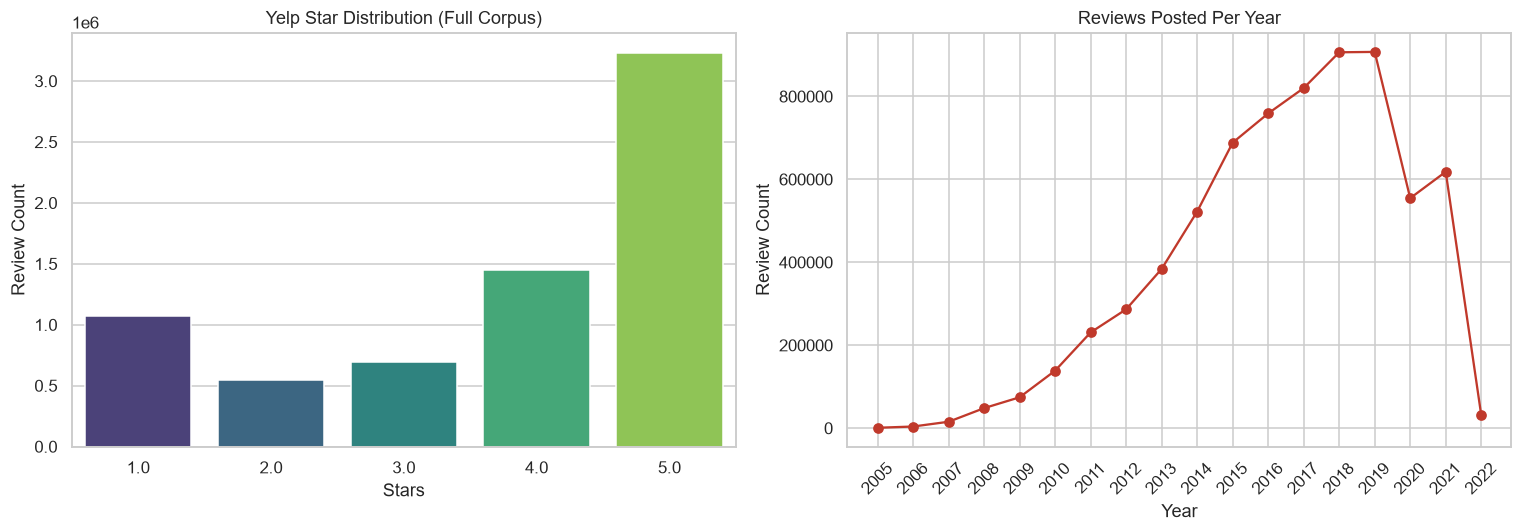

In [8]:
rating_dist = pd.read_sql_query("SELECT stars, COUNT(*) AS count FROM reviews GROUP BY stars ORDER BY stars", con)
yearly = pd.read_sql_query("SELECT substr(date,1,4) AS year, COUNT(*) AS count FROM reviews GROUP BY year ORDER BY year", con)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=rating_dist, x="stars", y="count", ax=axes[0], palette="viridis")
axes[0].set_title("Yelp Star Distribution (Full Corpus)")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Review Count")
axes[1].plot(yearly["year"], yearly["count"], marker="o", color="#c0392b")
axes[1].set_title("Reviews Posted Per Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Review Count")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Visualization: Corpus Rating and Temporal Profile

00:03:13 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:03:13 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:03:13 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:03:13 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


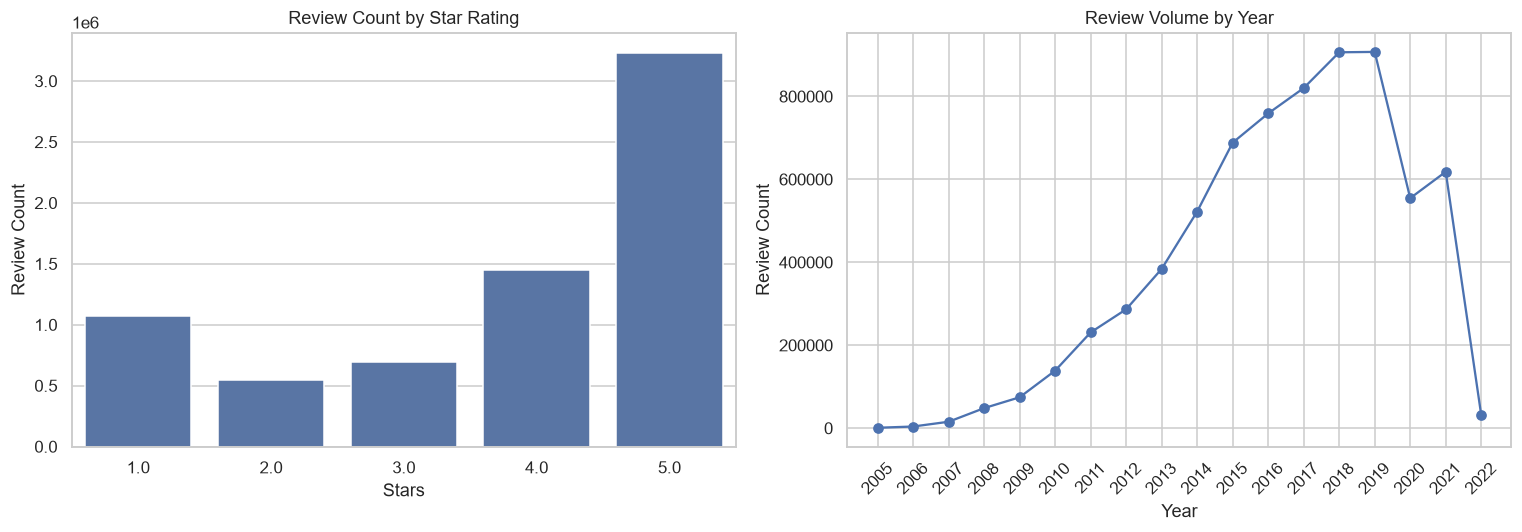

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=rating_dist, x="stars", y="count", ax=axes[0])
axes[0].set_title("Review Count by Star Rating")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Review Count")
axes[1].plot(yearly["year"], yearly["count"], marker="o")
axes[1].set_title("Review Volume by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Review Count")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 8. Exploring Review Length, Sentiment, and User Activity

00:05:17 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:05:17 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:05:17 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:05:17 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:05:17 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the

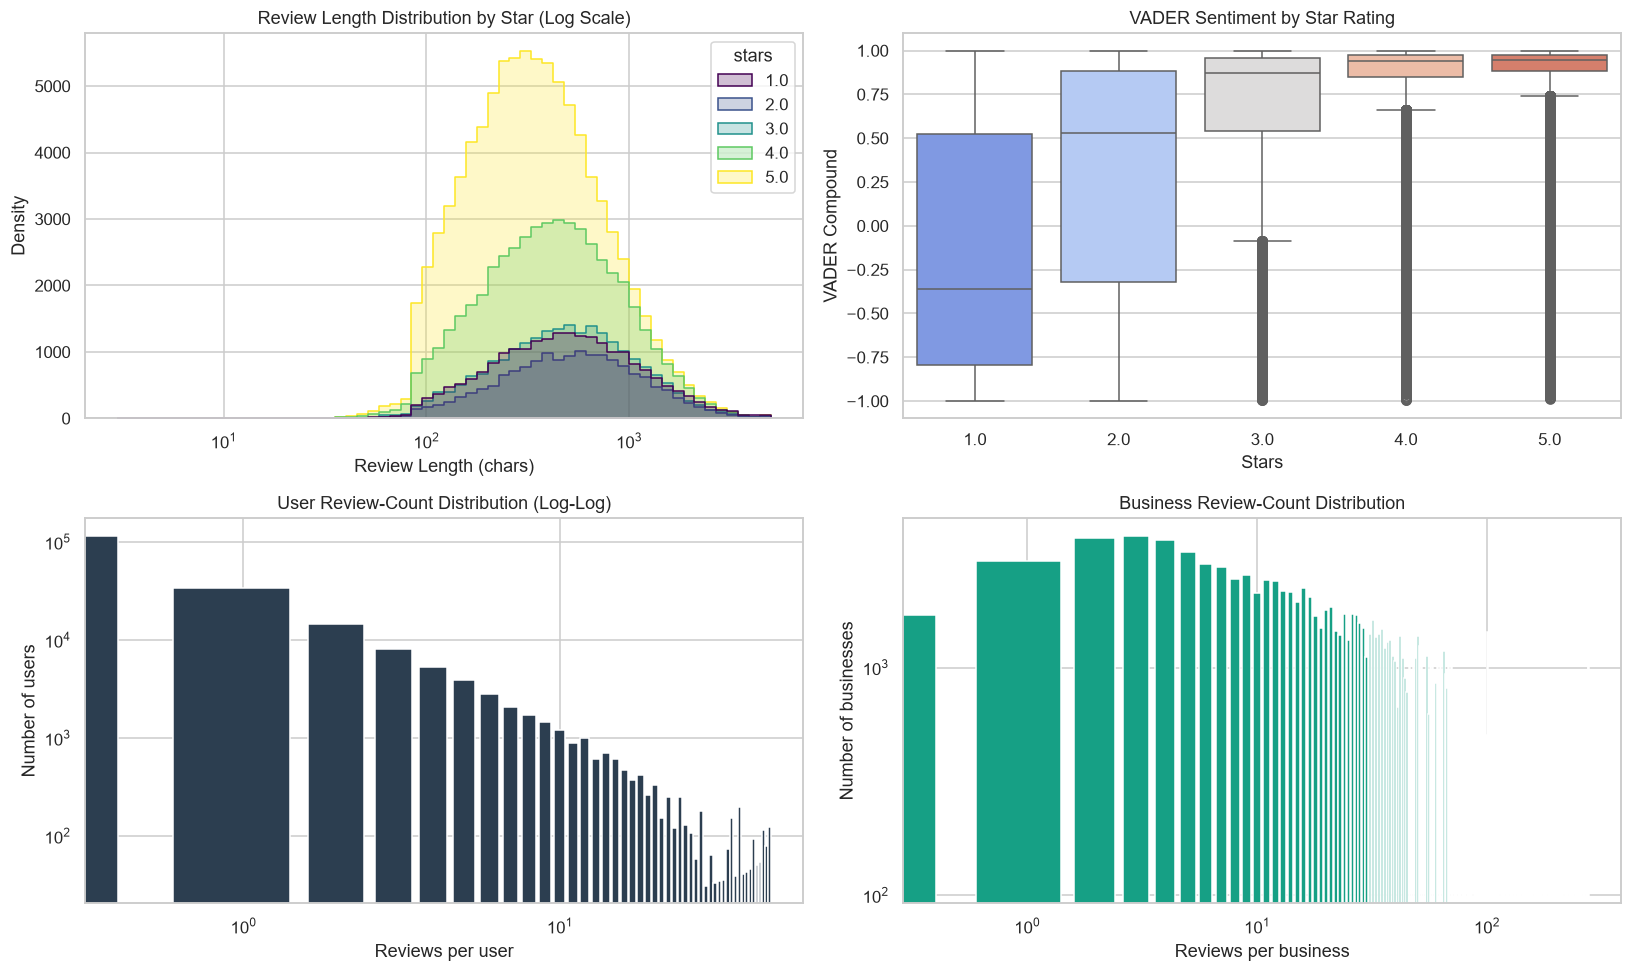

In [10]:
eda_df = pd.read_sql_query(
    "SELECT user_id, business_id, stars, date, text FROM reviews LIMIT 200000", con)
eda_df["text_len"] = eda_df["text"].str.len()
eda_df["user_review_count"] = eda_df.groupby("user_id")["user_id"].transform("size")
eda_df["biz_review_count"] = eda_df.groupby("business_id")["business_id"].transform("size")
sia = SentimentIntensityAnalyzer()
eda_df["vader_compound"] = eda_df["text"].astype(str).map(lambda t: sia.polarity_scores(t)["compound"])

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.histplot(data=eda_df, x="text_len", hue="stars", bins=60, log_scale=True,
             palette="viridis", ax=axes[0, 0], element="step")
axes[0, 0].set_title("Review Length Distribution by Star (Log Scale)")
axes[0, 0].set_xlabel("Review Length (chars)"); axes[0, 0].set_ylabel("Density")
sns.boxplot(data=eda_df, x="stars", y="vader_compound", palette="coolwarm", ax=axes[0, 1])
axes[0, 1].set_title("VADER Sentiment by Star Rating")
axes[0, 1].set_xlabel("Stars"); axes[0, 1].set_ylabel("VADER Compound")
user_rc = eda_df["user_review_count"].value_counts().sort_index()
axes[1, 0].bar(user_rc.index.astype(str), user_rc.values, color="#2c3e50")
axes[1, 0].set_yscale("log")
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("User Review-Count Distribution (Log-Log)")
axes[1, 0].set_xlabel("Reviews per user"); axes[1, 0].set_ylabel("Number of users")
biz_rc = eda_df["biz_review_count"].value_counts().sort_index()
axes[1, 1].bar(biz_rc.index.astype(str), biz_rc.values, color="#16a085")
axes[1, 1].set_xscale("log"); axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Business Review-Count Distribution")
axes[1, 1].set_xlabel("Reviews per business"); axes[1, 1].set_ylabel("Number of businesses")
plt.tight_layout()
plt.show()

### Visualization: Review Length and Sentiment Relationships

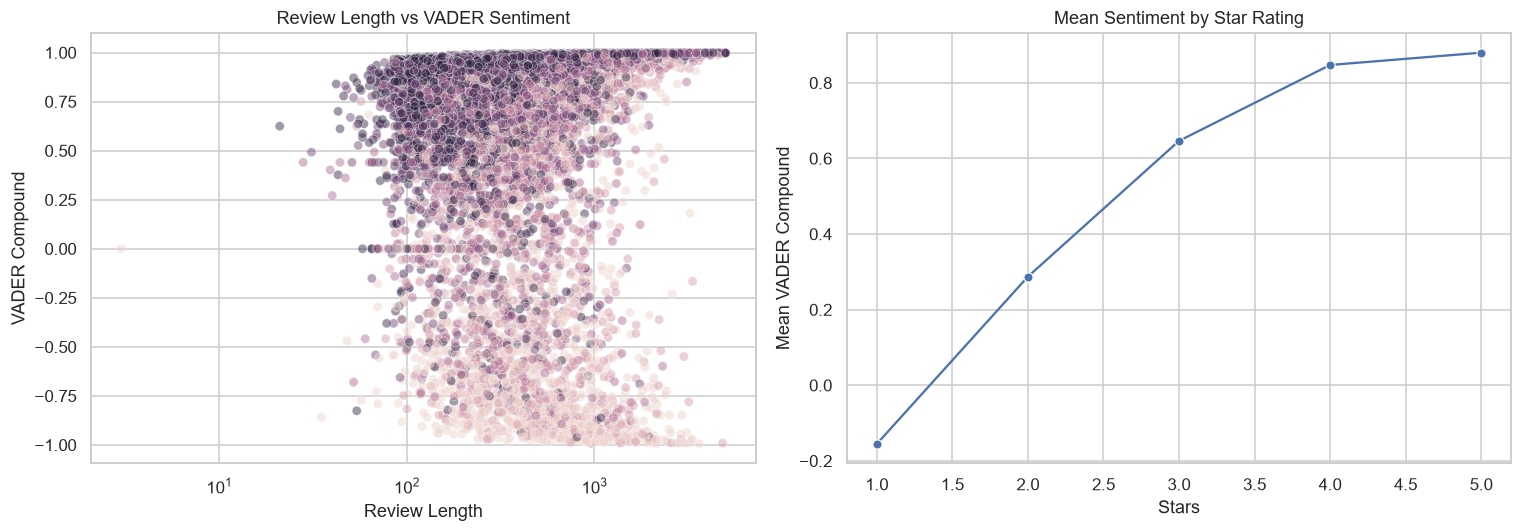

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=eda_df.sample(min(15000, len(eda_df)), random_state=SEED), x="text_len", y="vader_compound", hue="stars", alpha=0.45, ax=axes[0], legend=False)
axes[0].set_xscale("log")
axes[0].set_title("Review Length vs VADER Sentiment")
axes[0].set_xlabel("Review Length")
axes[0].set_ylabel("VADER Compound")
sentiment_by_star = eda_df.groupby("stars")["vader_compound"].mean().reset_index()
sns.lineplot(data=sentiment_by_star, x="stars", y="vader_compound", marker="o", ax=axes[1])
axes[1].set_title("Mean Sentiment by Star Rating")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Mean VADER Compound")
plt.tight_layout()
plt.show()

## 9. Sampling a Memory-Efficient Review Subset

In [12]:
t0 = time.perf_counter()
eligible_biz = pd.read_sql_query(
    "SELECT business_id FROM reviews GROUP BY business_id HAVING COUNT(*) >= 20", con)["business_id"].tolist()
rng = np.random.RandomState(SEED)
if not eligible_biz:
    raise RuntimeError("No businesses have at least 20 reviews; check that the Yelp review dataset was extracted correctly.")
eligible_biz_sample = rng.choice(eligible_biz, size=min(len(eligible_biz), 2000), replace=False).tolist()
biz_placeholders = ",".join(["?"] * len(eligible_biz_sample))
strata_query = (
    "SELECT user_id, business_id, stars, date, text, useful, funny, cool "
    "FROM reviews WHERE business_id IN (" + biz_placeholders + ")"
)
candidate_df = pd.read_sql_query(strata_query, con, params=eligible_biz_sample)
candidate_df["date"] = pd.to_datetime(candidate_df["date"], errors="coerce")
candidate_df = candidate_df.dropna(subset=["date"]).reset_index(drop=True)
candidate_df["stars_int"] = candidate_df["stars"].astype(int)
strata_sizes = (candidate_df.groupby("stars_int").size() / len(candidate_df) * CONFIG["SAMPLE_TARGET"]).round().astype(int)
sample_parts = []
for star_val, n_take in strata_sizes.items():
    sub = candidate_df[candidate_df["stars_int"] == star_val]
    take = min(n_take, len(sub))
    sample_parts.append(sub.sample(n=take, random_state=SEED))
sample_df = pd.concat(sample_parts, ignore_index=True)
sample_df = sample_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
sample_df = sample_df.drop(columns=["stars_int"])
TIMING["sampling"] = time.perf_counter() - t0
logger.info("Sampled reviews: %d | unique users: %d | unique businesses: %d (took %.1fs)",
            len(sample_df), sample_df["user_id"].nunique(), sample_df["business_id"].nunique(), TIMING["sampling"])
display(sample_df.head())

00:05:41 | INFO | Sampled reviews: 20000 | unique users: 18739 | unique businesses: 1954 (took 20.4s)


,user_id,business_id,stars,date,text,useful,funny,cool
0,8bZ9QiMWMpAka36qHh2OSg,_0JAjja8Pc2StBrhEgdf5Q,4.0,2015-02-04 04:41:39,Great chicken salad sandwich! Bring back the m...,1,0,0
1,c7TWNsZ9OgoYE4Dye009kg,LJNhMIW91t71SpEQgmrvdw,1.0,2018-05-25 15:27:40,Called to have them come and give me a estimat...,3,0,0
2,loleIg4lJL4ANcdiBuIVkA,iwDX85LRraB9vl6J3Oo-uA,4.0,2015-06-14 02:40:42,It's nice to find a non-chain restaurant with ...,3,1,1
3,4OR-2c_0jE74xszQnz3H2g,h7TO_IsmLCYmKKDVOOIeFw,1.0,2010-08-08 18:10:16,Reservations were easy and friendly. The decor...,0,0,0
4,eWv4QOGX1XNjLiwAMluehw,fcMloKLDT55hhhynDQhN3w,5.0,2018-01-17 22:01:42,I love this hidden gem just off Lafayette rd! ...,2,0,1


## 10. Auditing Missing Values and Edge Cases

,check,value
0,empty_reviews,0
1,duplicate_reviews,0
2,self_reviews,0
3,out_of_range_dates,0
4,invalid_dates,0
5,date_min,2005-07-31 04:50:20
6,date_max,2022-01-19 19:05:57


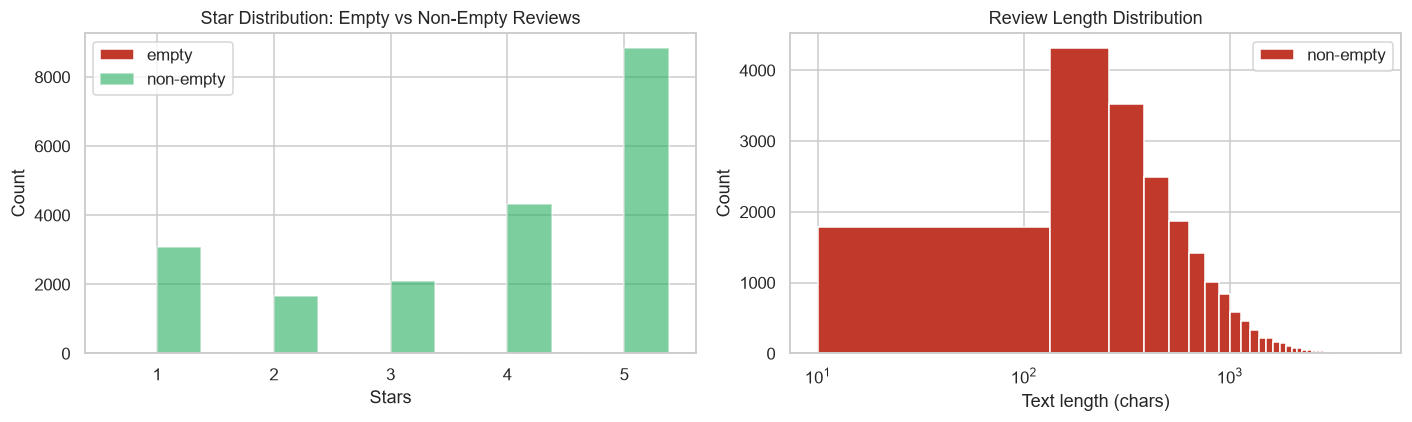

In [13]:
sample_df = sample_df.copy()

sample_df["text"] = sample_df["text"].fillna("").astype(str)
sample_df["text_len"] = sample_df["text"].str.len()

empty_mask = sample_df["text"].str.strip().eq("")
empty_count = int(empty_mask.sum())

sample_df["stars_numeric"] = pd.to_numeric(sample_df["stars"], errors="coerce")

star_values = sample_df["stars_numeric"].dropna().unique()
star_values = sorted(star_values.tolist())

empty_stars = (
    sample_df.loc[empty_mask, "stars_numeric"]
    .value_counts()
    .reindex(star_values, fill_value=0)
    .sort_index()
)

nonempty_stars = (
    sample_df.loc[~empty_mask, "stars_numeric"]
    .value_counts()
    .reindex(star_values, fill_value=0)
    .sort_index()
)

empty_lengths = sample_df.loc[empty_mask, "text_len"].to_numpy()
nonempty_lengths = sample_df.loc[~empty_mask, "text_len"].to_numpy()

duplicate_mask = sample_df.duplicated(
    subset=["user_id", "business_id", "date", "text"],
    keep=False
)

dup_keys = int(sample_df.duplicated(
    subset=["user_id", "business_id", "date", "text"]
).sum())

self_review_users = int(
    sample_df["user_id"].astype(str).eq(
        sample_df["business_id"].astype(str)
    ).sum()
)

sample_df["date_parsed"] = pd.to_datetime(
    sample_df["date"],
    errors="coerce"
)

date_min = sample_df["date_parsed"].min()
date_max = sample_df["date_parsed"].max()

valid_dates = sample_df["date_parsed"].notna()

out_of_range_mask = (
    valid_dates
    & (
        (sample_df["date_parsed"] < pd.Timestamp("2004-01-01"))
        | (sample_df["date_parsed"] > pd.Timestamp.now())
    )
)

out_of_range = int(out_of_range_mask.sum())

invalid_dates = int((~valid_dates).sum())

audit = pd.DataFrame({
    "check": [
        "empty_reviews",
        "duplicate_reviews",
        "self_reviews",
        "out_of_range_dates",
        "invalid_dates",
        "date_min",
        "date_max"
    ],
    "value": [
        empty_count,
        dup_keys,
        self_review_users,
        out_of_range,
        invalid_dates,
        str(date_min),
        str(date_max)
    ]
})

display(audit)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

if len(star_values) > 0:
    x = np.arange(len(star_values))
    width = 0.38

    axes[0].bar(
        x - width / 2,
        empty_stars.values,
        width=width,
        color="#c0392b",
        label="empty"
    )

    axes[0].bar(
        x + width / 2,
        nonempty_stars.values,
        width=width,
        color="#27ae60",
        alpha=0.6,
        label="non-empty"
    )

    star_labels = [
        str(int(value)) if float(value).is_integer() else str(value)
        for value in star_values
    ]

    axes[0].set_xticks(x)
    axes[0].set_xticklabels(star_labels)

else:
    axes[0].text(
        0.5,
        0.5,
        "No valid star ratings available",
        ha="center",
        va="center",
        transform=axes[0].transAxes
    )

axes[0].set_title("Star Distribution: Empty vs Non-Empty Reviews")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Count")
axes[0].legend()

hist_data = []
hist_labels = []

if len(empty_lengths) > 0:
    hist_data.append(empty_lengths)
    hist_labels.append("empty")

if len(nonempty_lengths) > 0:
    hist_data.append(nonempty_lengths)
    hist_labels.append("non-empty")

if len(hist_data) > 0:
    axes[1].hist(
        hist_data,
        bins=40,
        label=hist_labels,
        color=["#c0392b", "#27ae60"][:len(hist_data)]
    )

    axes[1].set_xscale("symlog", linthresh=1)
    axes[1].legend()

else:
    axes[1].text(
        0.5,
        0.5,
        "No review text available",
        ha="center",
        va="center",
        transform=axes[1].transAxes
    )

axes[1].set_title("Review Length Distribution")
axes[1].set_xlabel("Text length (chars)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

sample_df = sample_df.loc[~empty_mask].reset_index(drop=True)

sample_df = sample_df.drop(
    columns=["stars_numeric", "date_parsed"],
    errors="ignore"
)

## 11. Preprocessing Review Text for Transformer Encoding

In [14]:
import html
def minimal_preprocess(t, lowercase=True):
    t = html.unescape(str(t))
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    if lowercase:
        t = t.lower()
    return t

sample_df["clean_text_lower"] = sample_df["text"].map(lambda t: minimal_preprocess(t, lowercase=True))
sample_df["clean_text_preserved"] = sample_df["text"].map(lambda t: minimal_preprocess(t, lowercase=False))

empty_after_clean = int(sample_df["clean_text_lower"].eq("").sum())
logger.info("Reviews collapsed to empty after preprocessing: %d", empty_after_clean)
sample_df = sample_df[sample_df["clean_text_lower"].str.len() > 0].reset_index(drop=True)

display(sample_df[["text", "clean_text_lower", "clean_text_preserved", "stars"]].head(6))

00:05:43 | INFO | Reviews collapsed to empty after preprocessing: 0


,text,clean_text_lower,clean_text_preserved,stars
0,Great chicken salad sandwich! Bring back the m...,great chicken salad sandwich! bring back the m...,Great chicken salad sandwich! Bring back the m...,4.0
1,Called to have them come and give me a estimat...,called to have them come and give me a estimat...,Called to have them come and give me a estimat...,1.0
2,It's nice to find a non-chain restaurant with ...,it's nice to find a non-chain restaurant with ...,It's nice to find a non-chain restaurant with ...,4.0
3,Reservations were easy and friendly. The decor...,reservations were easy and friendly. the decor...,Reservations were easy and friendly. The decor...,1.0
4,I love this hidden gem just off Lafayette rd! ...,i love this hidden gem just off lafayette rd! ...,I love this hidden gem just off Lafayette rd! ...,5.0
5,The FOH staff that works here are always so sw...,the foh staff that works here are always so sw...,The FOH staff that works here are always so sw...,5.0


## 12. Extracting Sentence-Transformer Embeddings

In [15]:
t0 = time.perf_counter()
encoder_results = []
encoder_models = {}
for model_name in CONFIG["ENCODER_CANDIDATES"]:
    t_e = time.perf_counter()
    enc = SentenceTransformer(model_name)
    emb_lower = enc.encode(sample_df["clean_text_lower"].tolist(),
                           batch_size=CONFIG["ENCODER_BATCH"], show_progress_bar=False,
                           convert_to_numpy=True, normalize_embeddings=True)
    enc_time = time.perf_counter() - t_e
    encoder_models[model_name] = (enc, emb_lower)
    encoder_results.append({
        "encoder": model_name,
        "dim": emb_lower.shape[1],
        "wall_seconds": round(enc_time, 2),
        "samples_per_sec": round(len(emb_lower) / enc_time, 1)
    })
    logger.info("Encoder %s done in %.1fs (dim=%d)", model_name, enc_time, emb_lower.shape[1])

encoder_compare_df = pd.DataFrame(encoder_results)
display(encoder_compare_df)
TIMING["embedding"] = time.perf_counter() - t0

00:05:43 | INFO | No device provided, using cpu
00:05:44 | INFO | HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
00:05:44 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
00:05:44 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
00:05:44 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
00:05:45 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
00:05:45 | INFO | HTTP Request: 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

00:05:48 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
00:05:48 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
00:05:48 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
00:05:49 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
00:05:49 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
00:05:49 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/tokenizer_config

,encoder,dim,wall_seconds,samples_per_sec
0,sentence-transformers/all-MiniLM-L6-v2,384,431.14,46.4


## 13. Computing Temporal Sentiment Trajectories

00:13:46 | INFO | Business-month trajectories: 16749


,business_id,year_month,mean_sentiment,std_sentiment,review_volume,sent_se
0,-1EGqUQFBmGEp76CE-Zk4Q,2018-09,0.6124,0.0,1,0.0
1,-1EGqUQFBmGEp76CE-Zk4Q,2019-01,0.8067,0.0,1,0.0
2,-1EGqUQFBmGEp76CE-Zk4Q,2020-02,0.9664,0.0,1,0.0
3,-1EGqUQFBmGEp76CE-Zk4Q,2021-09,0.9913,0.0,1,0.0
4,-1zRvh3yjKAa2eYggRKbuw,2012-04,-0.8442,0.0,1,0.0


00:13:46 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:13:46 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:13:46 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:13:46 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:13:46 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the

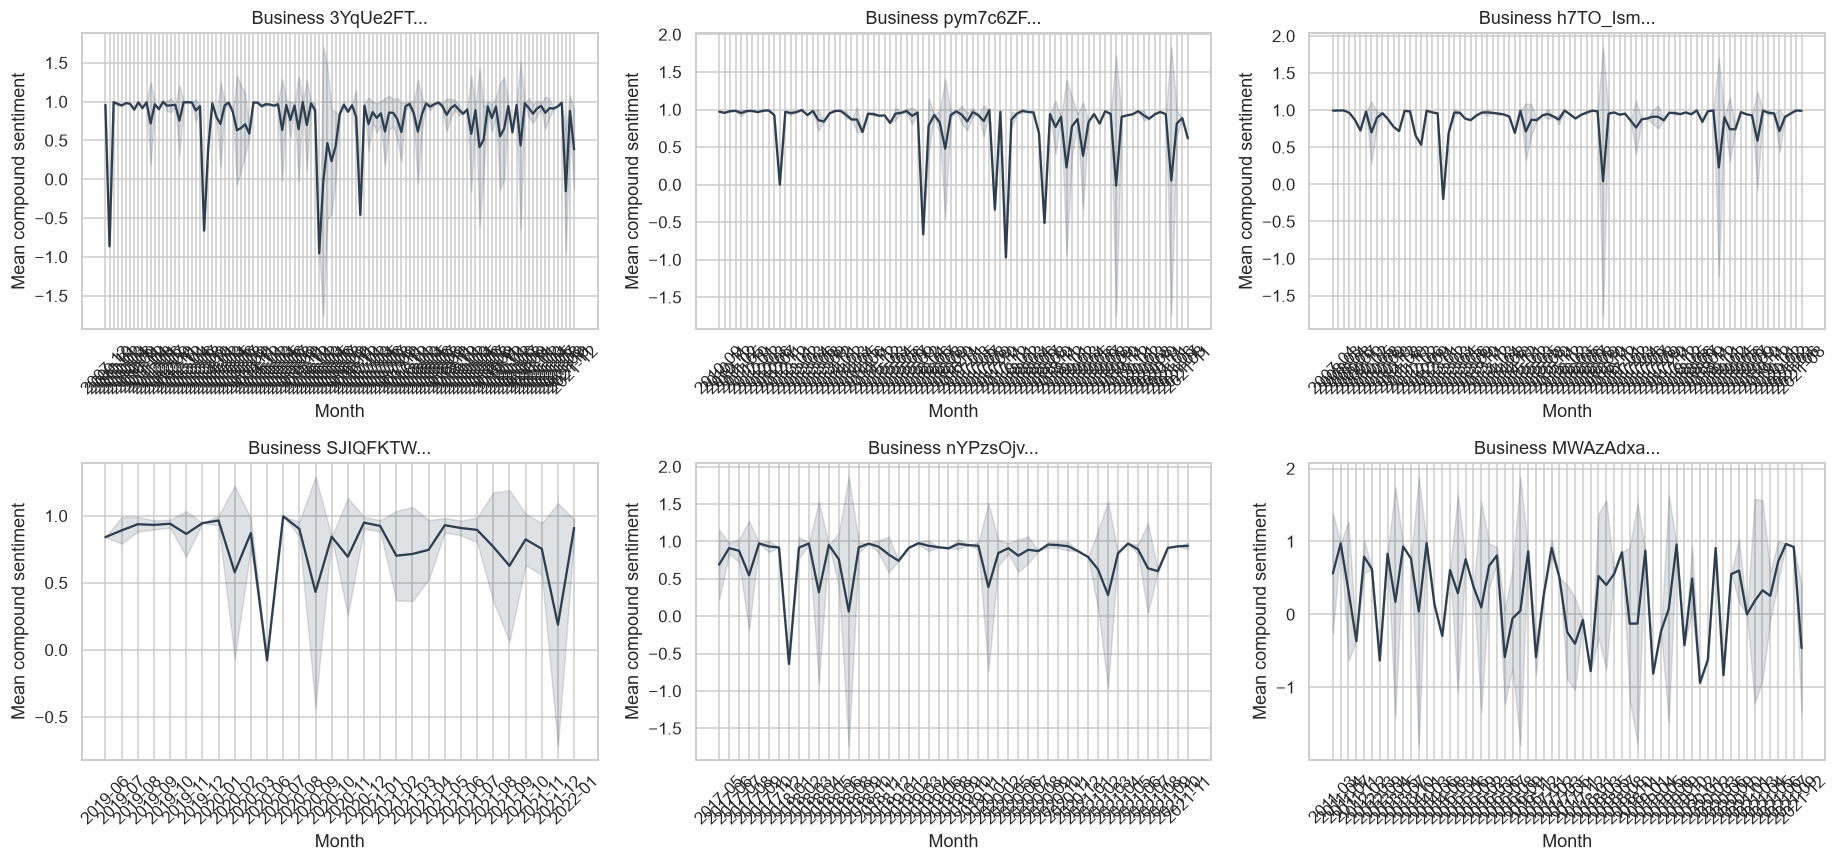

In [16]:
sia = SentimentIntensityAnalyzer()
sample_df["vader_compound"] = sample_df["clean_text_lower"].map(lambda t: sia.polarity_scores(t)["compound"])
sample_df["vader_pos"] = sample_df["clean_text_lower"].map(lambda t: sia.polarity_scores(t)["pos"])
sample_df["vader_neg"] = sample_df["clean_text_lower"].map(lambda t: sia.polarity_scores(t)["neg"])
sample_df["vader_neu"] = sample_df["clean_text_lower"].map(lambda t: sia.polarity_scores(t)["neu"])

sample_df["year_month"] = sample_df["date"].dt.to_period("M").astype(str)
biz_monthly = (sample_df.groupby(["business_id", "year_month"])
               .agg(mean_sentiment=("vader_compound", "mean"),
                    std_sentiment=("vader_compound", "std"),
                    review_volume=("vader_compound", "size"))
               .reset_index())
biz_monthly["std_sentiment"] = biz_monthly["std_sentiment"].fillna(0)
biz_monthly["sent_se"] = biz_monthly["std_sentiment"] / np.sqrt(biz_monthly["review_volume"].clip(lower=1))
logger.info("Business-month trajectories: %d", len(biz_monthly))
display(biz_monthly.head())

top_businesses = sample_df["business_id"].value_counts().head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, bid in zip(axes.flat, top_businesses):
    sub = biz_monthly[biz_monthly["business_id"] == bid].sort_values("year_month")
    ax.plot(sub["year_month"], sub["mean_sentiment"], color="#2c3e50", lw=1.5)
    ax.fill_between(sub["year_month"],
                    sub["mean_sentiment"] - 1.96 * sub["sent_se"],
                    sub["mean_sentiment"] + 1.96 * sub["sent_se"],
                    color="#2c3e50", alpha=0.15, label="95% CI")
    ax.set_title(f"Business {bid[:8]}...")
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("Month"); ax.set_ylabel("Mean compound sentiment")
plt.tight_layout()
plt.show()

## 14. Constructing the User-Business Interaction Graph

00:13:49 | INFO | Graph built: 20693 nodes (18739 users, 1954 businesses), 19890 edges


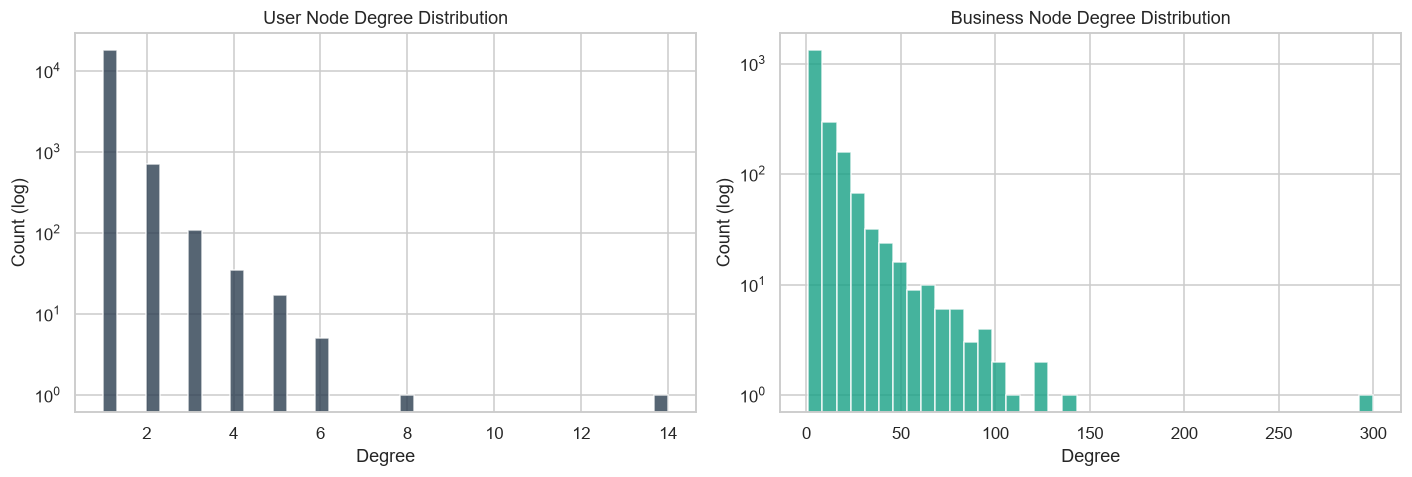

In [17]:
edges = (sample_df.groupby(["user_id", "business_id"]).size().rename("weight").reset_index())

G = nx.Graph()
for _, row in edges.iterrows():
    u_node = "U:" + row["user_id"]
    b_node = "B:" + row["business_id"]
    if G.has_edge(u_node, b_node):
        G[u_node][b_node]["weight"] += int(row["weight"])
    else:
        G.add_edge(u_node, b_node, weight=int(row["weight"]))

user_nodes = [n for n in G.nodes if n.startswith("U:")]
biz_nodes = [n for n in G.nodes if n.startswith("B:")]
logger.info("Graph built: %d nodes (%d users, %d businesses), %d edges",
            G.number_of_nodes(), len(user_nodes), len(biz_nodes), G.number_of_edges())

user_deg = dict(G.degree(user_nodes))
biz_deg = dict(G.degree(biz_nodes))
sample_df["user_deg"] = sample_df["user_id"].map(lambda u: user_deg.get("U:" + u, 0))
sample_df["biz_deg"] = sample_df["business_id"].map(lambda b: biz_deg.get("B:" + b, 0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
u_deg_vals = np.array(list(user_deg.values()))
b_deg_vals = np.array(list(biz_deg.values()))
axes[0].hist(u_deg_vals, bins=40, color="#2c3e50", alpha=0.8)
axes[0].set_yscale("log")
axes[0].set_title("User Node Degree Distribution")
axes[0].set_xlabel("Degree"); axes[0].set_ylabel("Count (log)")
axes[1].hist(b_deg_vals, bins=40, color="#16a085", alpha=0.8)
axes[1].set_yscale("log")
axes[1].set_title("Business Node Degree Distribution")
axes[1].set_xlabel("Degree"); axes[1].set_ylabel("Count (log)")
plt.tight_layout()
plt.show()

## 15. Generating Graph Embeddings with Node2Vec

In [18]:
t0 = time.perf_counter()
n_workers = CONFIG["N2V_WORKERS"]
total_walks = G.number_of_nodes() * CONFIG["NUM_WALKS"]
logger.info("Node2Vec walk budget: %d walks, %d workers", total_walks, n_workers)

node2vec = Node2Vec(G, dimensions=CONFIG["EMBED_DIM"], walk_length=CONFIG["WALK_LENGTH"],
                    num_walks=CONFIG["NUM_WALKS"], workers=n_workers, seed=SEED, quiet=True)
n2v_model = node2vec.fit(window=CONFIG["WINDOW"], min_count=1, batch_words=512, epochs=CONFIG["EPOCHS_N2V"], seed=SEED)

user_emb = {n: n2v_model.wv[n] for n in user_nodes}
biz_emb = {n: n2v_model.wv[n] for n in biz_nodes}

user_emb_df = pd.DataFrame.from_dict(
    {u[2:]: user_emb[u] for u in user_nodes},
    orient="index", columns=[f"u_ge_{i}" for i in range(CONFIG["EMBED_DIM"])])

user_emb_df.index.name = "user_id"
user_emb_df = user_emb_df.reset_index()

biz_emb_df = pd.DataFrame.from_dict(
    {b[2:]: biz_emb[b] for b in biz_nodes},
    orient="index", columns=[f"b_ge_{i}" for i in range(CONFIG["EMBED_DIM"])])
biz_emb_df.index.name = "business_id"
biz_emb_df = biz_emb_df.reset_index()

TIMING["node2vec"] = time.perf_counter() - t0
logger.info("User embeddings: %s | Business embeddings: %s (took %.1fs)",
            user_emb_df.shape, biz_emb_df.shape, TIMING["node2vec"])
display(user_emb_df.head())

00:13:50 | INFO | Node2Vec walk budget: 206930 walks, 4 workers
00:14:05 | INFO | collecting all words and their counts
00:14:05 | INFO | PROGRESS: at sentence #0, processed 0 words, keeping 0 word types
00:14:05 | INFO | PROGRESS: at sentence #10000, processed 200000 words, keeping 20244 word types
00:14:05 | INFO | PROGRESS: at sentence #20000, processed 400000 words, keeping 20692 word types
00:14:06 | INFO | PROGRESS: at sentence #30000, processed 600000 words, keeping 20693 word types
00:14:06 | INFO | PROGRESS: at sentence #40000, processed 800000 words, keeping 20693 word types
00:14:06 | INFO | PROGRESS: at sentence #50000, processed 1000000 words, keeping 20693 word types
00:14:06 | INFO | PROGRESS: at sentence #60000, processed 1200000 words, keeping 20693 word types
00:14:06 | INFO | PROGRESS: at sentence #70000, processed 1400000 words, keeping 20693 word types
00:14:06 | INFO | PROGRESS: at sentence #80000, processed 1600000 words, keeping 20693 word types
00:14:06 | INFO 

,user_id,u_ge_0,u_ge_1,u_ge_2,u_ge_3,u_ge_4,u_ge_5,u_ge_6,u_ge_7,u_ge_8,...,u_ge_54,u_ge_55,u_ge_56,u_ge_57,u_ge_58,u_ge_59,u_ge_60,u_ge_61,u_ge_62,u_ge_63
0,--RYw4T-D2GlTSXqn1VBag,0.200850,-0.781492,0.279230,0.251736,-1.233861,-0.111610,0.332516,-1.105794,-0.268346,...,-0.479202,-0.926245,0.053471,-0.552358,0.745920,0.548440,-1.384519,-0.010077,0.677643,-0.964259
1,--vN7C-lXaBve7Sl02Y_9Q,0.210819,-1.225685,0.534290,-0.472332,-0.954816,0.508381,0.778581,-0.832207,-1.407496,...,0.227979,-0.330692,0.615862,-0.224131,0.788665,-0.114484,0.081871,-0.452234,0.341903,0.095814
2,--wc4pqlCDN99OItK_g-qQ,0.328653,-0.631220,0.038919,0.362611,0.437631,0.367892,0.070957,-0.716085,-0.526887,...,-0.220713,-0.095201,1.139036,-0.720253,-0.101361,-0.702212,-0.642159,0.160854,0.139415,-0.701473
3,-09N_lZ380irBMCo4mbaSQ,0.310025,-0.554361,0.199345,-0.070218,-0.846996,0.747252,0.283991,-0.801879,-0.449169,...,-0.831614,0.298030,0.810055,-0.549429,0.589179,-0.686085,-0.034976,0.227785,-0.243885,-0.152038
4,-0KosxqqMBYNfJ7VuvBYDQ,-0.609561,-0.838218,-0.674619,0.368365,-0.166578,0.076699,0.137758,-0.277238,-0.583344,...,-0.931242,-0.773122,0.546889,-0.998215,0.421459,0.038340,-0.041750,-0.604870,1.061220,0.025940


## 16. Engineering Behavioural Signals for Labelling

In [19]:
user_counts = sample_df.groupby("user_id").size().rename("user_review_count")
biz_stats = (sample_df.groupby("business_id")["stars"]
             .agg(["count", "mean", "std"])
             .rename(columns={"count": "biz_review_count",
                              "mean": "biz_avg_stars",
                              "std": "biz_std_stars"}))

sample_df = sample_df.merge(user_counts, on="user_id", how="left")
sample_df = sample_df.merge(biz_stats, on="business_id", how="left")
sample_df["star_deviation"] = (sample_df["stars"] - sample_df["biz_avg_stars"]).abs()
sample_df["text_len"] = sample_df["clean_text_lower"].str.len()
sample_df["extreme_rating"] = sample_df["stars"].isin([1, 5]).astype(int)
sample_df["singleton_user"] = (sample_df["user_review_count"] == 1).astype(int)

bursts = (sample_df.sort_values(["business_id", "date"])
          .groupby("business_id")["date"]
          .diff().dt.total_seconds().div(3600))
sample_df["hours_since_prev"] = bursts.fillna(99999)
sample_df["burst_window"] = (sample_df["hours_since_prev"] <= 24).astype(int)

logger.info("Behavioural signals engineered. Distribution summary:")
display(sample_df[["user_review_count", "biz_avg_stars", "star_deviation",
                   "text_len", "hours_since_prev", "extreme_rating",
                   "singleton_user", "burst_window"]].describe().T)

00:15:16 | INFO | Behavioural signals engineered. Distribution summary:


,count,mean,std,min,25%,50%,75%,max
user_review_count,20000.0,1.179400,0.699243,1.000000,1.000000,1.000000,1.000000,15.000000
biz_avg_stars,20000.0,3.705800,0.817838,1.000000,3.280000,3.857143,4.283186,5.000000
star_deviation,20000.0,0.971269,0.756562,0.000000,0.377778,0.800000,1.375000,3.846154
text_len,20000.0,564.349650,528.988008,10.000000,226.000000,401.000000,715.000000,4990.000000
hours_since_prev,20000.0,14046.882620,29265.331995,0.002778,627.794375,2268.186806,8277.257778,101911.094444
extreme_rating,20000.0,0.595850,0.490739,0.000000,0.000000,1.000000,1.000000,1.000000
singleton_user,20000.0,0.888750,0.314449,0.000000,1.000000,1.000000,1.000000,1.000000
burst_window,20000.0,0.019500,0.138278,0.000000,0.000000,0.000000,0.000000,1.000000


## 17. Constructing Pseudo-Labels Isolated from Features

In [20]:
suspect_score = (
    (sample_df["singleton_user"] * 2) +
    (sample_df["extreme_rating"] * 1) +
    (sample_df["star_deviation"] > 2).astype(int) * 2 +
    (sample_df["burst_window"] * 2) +
    (sample_df["text_len"] < 80).astype(int) * 1
)
sample_df["suspect_score"] = suspect_score
sample_df["pseudo_label"] = (suspect_score >= 4).astype(int)

label_counts = sample_df["pseudo_label"].value_counts().sort_index()
logger.info("Pseudo-label distribution: 0=%d  1=%d  (positive rate=%.4f)",
            int(label_counts.get(0, 0)), int(label_counts.get(1, 0)),
            sample_df["pseudo_label"].mean())
display(sample_df[["user_review_count", "biz_avg_stars", "star_deviation",
                   "text_len", "hours_since_prev", "suspect_score", "pseudo_label"]].describe().T)

00:15:16 | INFO | Pseudo-label distribution: 0=17700  1=2300  (positive rate=0.1150)


,count,mean,std,min,25%,50%,75%,max
user_review_count,20000.0,1.179400,0.699243,1.000000,1.000000,1.000000,1.000000,15.000000
biz_avg_stars,20000.0,3.705800,0.817838,1.000000,3.280000,3.857143,4.283186,5.000000
star_deviation,20000.0,0.971269,0.756562,0.000000,0.377778,0.800000,1.375000,3.846154
text_len,20000.0,564.349650,528.988008,10.000000,226.000000,401.000000,715.000000,4990.000000
hours_since_prev,20000.0,14046.882620,29265.331995,0.002778,627.794375,2268.186806,8277.257778,101911.094444
suspect_score,20000.0,2.628450,1.142920,0.000000,2.000000,3.000000,3.000000,8.000000
pseudo_label,20000.0,0.115000,0.319030,0.000000,0.000000,0.000000,0.000000,1.000000


### Visualization: Pseudo-Label Distribution and Suspicion Score

00:15:16 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:15:16 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:15:16 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:15:16 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


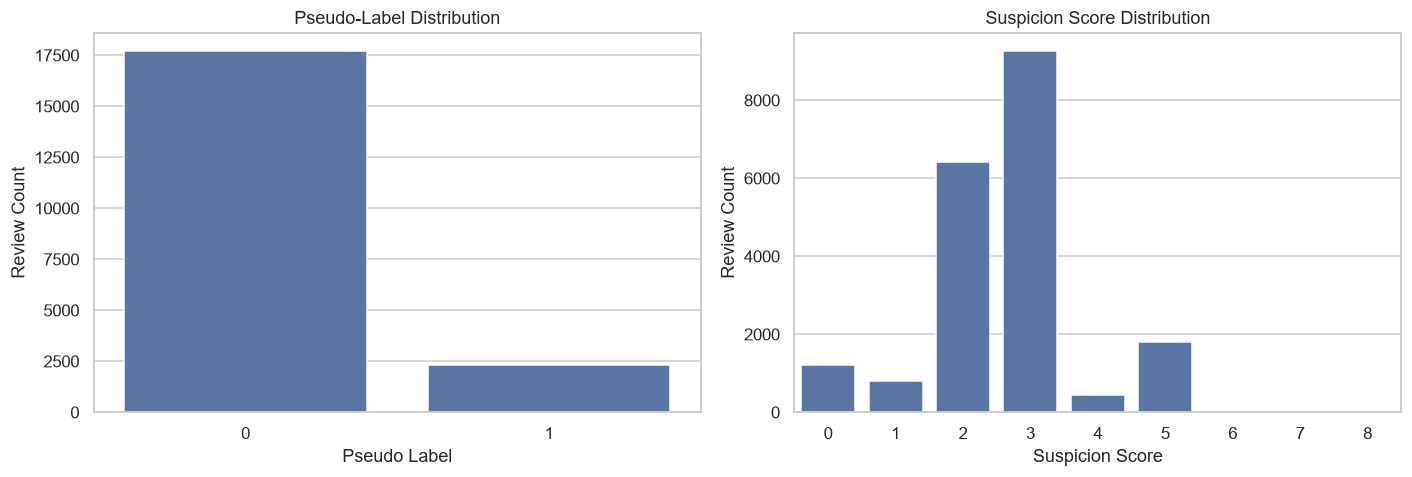

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=sample_df, x="pseudo_label", ax=axes[0])
axes[0].set_title("Pseudo-Label Distribution")
axes[0].set_xlabel("Pseudo Label")
axes[0].set_ylabel("Review Count")
score_dist = sample_df["suspect_score"].value_counts().sort_index().reset_index()
score_dist.columns = ["suspect_score", "count"]
sns.barplot(data=score_dist, x="suspect_score", y="count", ax=axes[1])
axes[1].set_title("Suspicion Score Distribution")
axes[1].set_xlabel("Suspicion Score")
axes[1].set_ylabel("Review Count")
plt.tight_layout()
plt.show()

## 18. Validating the Pseudo-Label Heuristic

00:15:17 | INFO | Heuristic stability check (n=81): precision=1.000 recall=1.000 f1=1.000


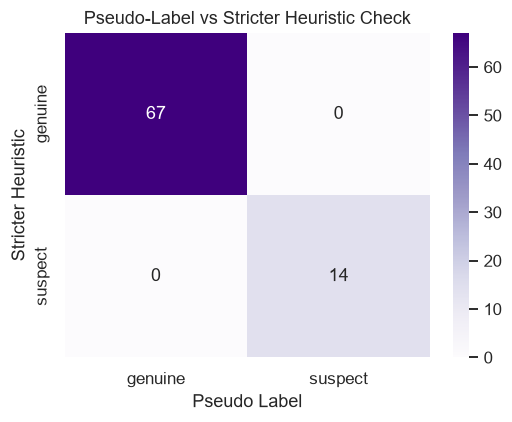

,text,clean_text_lower,stars,text_len,user_review_count,burst_window,suspect_score,pseudo_label,strict_heuristic_label
10650,I took my baby snowball here for his haircut. ...,i took my baby snowball here for his haircut. ...,3.0,592,1,0,2,0,0
8668,"Since this place is so close to my office, it'...","since this place is so close to my office, it'...",4.0,412,3,0,0,0,0
3002,Me and my family have been coming here ever si...,me and my family have been coming here ever si...,3.0,459,1,0,2,0,0
19771,I walked in and it seemed as though the staff ...,i walked in and it seemed as though the staff ...,2.0,1125,1,0,2,0,0
8115,This is a really cute tasting room in the funk...,this is a really cute tasting room in the funk...,4.0,580,2,0,0,0,0
3525,"My nails look gorgeous when I leave, but my ge...","my nails look gorgeous when i leave, but my ge...",4.0,190,1,0,2,0,0
16441,Situation was dire: I had a slab leak under th...,situation was dire: i had a slab leak under th...,4.0,2186,3,0,0,0,0
16296,Here for almost 2 hours. Came for leaky tire r...,here for almost 2 hours. came for leaky tire r...,1.0,181,1,0,5,1,1
12566,"Not worth the drive. Poor service, dull ambien...","not worth the drive. poor service, dull ambien...",2.0,108,1,0,2,0,0
19393,My complaint got escalated to a department tha...,my complaint got escalated to a department tha...,4.0,98,1,0,2,0,0


In [22]:
val_idx_audit = sample_df.sample(n=min(CONFIG["VALID_SAMPLE_N"], len(sample_df)), random_state=SEED).index
val_df = sample_df.loc[val_idx_audit, ["text", "clean_text_lower", "stars", "text_len",
                                      "user_review_count", "burst_window",
                                      "suspect_score", "pseudo_label"]].copy()
val_df["strict_heuristic_label"] = val_df["suspect_score"].apply(
    lambda s: 1 if s >= 5 else (0 if s <= 2 else np.nan))
val_df = val_df.dropna(subset=["strict_heuristic_label"]).copy()
val_df["strict_heuristic_label"] = val_df["strict_heuristic_label"].astype(int)

pseudo_precision = precision_score(val_df["strict_heuristic_label"], val_df["pseudo_label"], zero_division=0)
pseudo_recall = recall_score(val_df["strict_heuristic_label"], val_df["pseudo_label"], zero_division=0)
pseudo_f1 = f1_score(val_df["strict_heuristic_label"], val_df["pseudo_label"], zero_division=0)
cm_pseudo = confusion_matrix(val_df["strict_heuristic_label"], val_df["pseudo_label"])

logger.info("Heuristic stability check (n=%d): precision=%.3f recall=%.3f f1=%.3f",
            len(val_df), pseudo_precision, pseudo_recall, pseudo_f1)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_pseudo, annot=True, fmt="d", cmap="Purples", ax=ax,
            xticklabels=["genuine", "suspect"], yticklabels=["genuine", "suspect"])
ax.set_title("Pseudo-Label vs Stricter Heuristic Check")
ax.set_xlabel("Pseudo Label"); ax.set_ylabel("Stricter Heuristic")
plt.tight_layout(); plt.show()
display(val_df.head(15))

## 19. Fusing Text, Graph, and Sentiment Features

In [23]:
selected_encoder = CONFIG["ENCODER_CANDIDATES"][0]
embeddings_arr = encoder_models[selected_encoder][1]
text_emb_cols = [f"text_emb_{i}" for i in range(embeddings_arr.shape[1])]
text_emb_df = pd.DataFrame(embeddings_arr, columns=text_emb_cols)
text_emb_df["_row_id"] = np.arange(len(text_emb_df))

feature_df = sample_df[["user_id", "business_id", "stars", "date",
                        "vader_compound", "vader_pos", "vader_neg", "vader_neu",
                        "user_deg", "biz_deg", "pseudo_label"]].copy().reset_index(drop=True)
feature_df["_row_id"] = np.arange(len(feature_df))

feature_df = feature_df.merge(text_emb_df, on="_row_id", how="left")
feature_df = feature_df.merge(user_emb_df, on="user_id", how="left")
feature_df = feature_df.merge(biz_emb_df, on="business_id", how="left")
feature_df = feature_df.drop(columns=["_row_id"])

n_missing_user_emb = int(feature_df[[f"u_ge_{i}" for i in range(CONFIG["EMBED_DIM"])]].isna().any(axis=1).sum())
n_missing_biz_emb = int(feature_df[[f"b_ge_{i}" for i in range(CONFIG["EMBED_DIM"])]].isna().any(axis=1).sum())
logger.info("Missing user embeddings: %d | Missing business embeddings: %d",
            n_missing_user_emb, n_missing_biz_emb)
feature_df = feature_df.fillna(0.0)

assert len(feature_df) == len(sample_df), f"Row count mismatch: {len(feature_df)} vs {len(sample_df)}"
assert feature_df.isna().sum().sum() == 0, "NaNs present after fusion"

LABELING_FEATURES = {"singleton_user", "extreme_rating", "star_deviation",
                     "burst_window", "text_len", "hours_since_prev",
                     "suspect_score", "biz_avg_stars", "biz_std_stars",
                     "biz_review_count", "user_review_count"}
feature_cols = [c for c in feature_df.columns if c not in {"user_id", "business_id", "date", "pseudo_label"}]
leakage = [c for c in feature_cols if c in LABELING_FEATURES]
assert not leakage, f"Labelling features leaked into X: {leakage}"

X = feature_df[feature_cols].values.astype(np.float32)
y = feature_df["pseudo_label"].values.astype(int)
feature_names = feature_cols
logger.info("Final feature matrix: %s | positive rate: %.4f | features: %d",
            X.shape, y.mean(), len(feature_names))
display(feature_df.head())

00:15:17 | INFO | Missing user embeddings: 0 | Missing business embeddings: 0
00:15:18 | INFO | Final feature matrix: (20000, 519) | positive rate: 0.1150 | features: 519


,user_id,business_id,stars,date,vader_compound,vader_pos,vader_neg,vader_neu,user_deg,biz_deg,...,b_ge_54,b_ge_55,b_ge_56,b_ge_57,b_ge_58,b_ge_59,b_ge_60,b_ge_61,b_ge_62,b_ge_63
0,8bZ9QiMWMpAka36qHh2OSg,_0JAjja8Pc2StBrhEgdf5Q,4.0,2015-02-04 04:41:39,0.9660,0.308,0.000,0.692,2,11,...,-1.236328,-1.962373,0.385781,-1.670419,0.378271,-0.399892,-0.451981,-0.413526,0.884065,0.070304
1,c7TWNsZ9OgoYE4Dye009kg,LJNhMIW91t71SpEQgmrvdw,1.0,2018-05-25 15:27:40,-0.8702,0.018,0.103,0.879,1,3,...,-0.342028,0.530327,1.667724,-0.117571,-0.223507,0.109420,-0.034241,-0.119236,-0.131915,0.211223
2,loleIg4lJL4ANcdiBuIVkA,iwDX85LRraB9vl6J3Oo-uA,4.0,2015-06-14 02:40:42,0.9738,0.459,0.000,0.541,1,43,...,-0.449852,0.738429,0.725426,-1.016042,-0.283768,-0.943172,-0.719892,0.455152,0.407253,-0.204501
3,4OR-2c_0jE74xszQnz3H2g,h7TO_IsmLCYmKKDVOOIeFw,1.0,2010-08-08 18:10:16,0.8519,0.126,0.041,0.833,1,124,...,-0.046862,-0.508474,0.834599,-1.314811,-0.087395,-0.138654,-1.142873,-0.155625,0.557499,-0.582831
4,eWv4QOGX1XNjLiwAMluehw,fcMloKLDT55hhhynDQhN3w,5.0,2018-01-17 22:01:42,0.9616,0.221,0.023,0.756,1,11,...,-0.535608,-0.030623,1.127807,-0.442606,-0.845239,-1.377451,-0.300264,-0.149986,-0.423293,-1.096763


### Visualization: Feature-Fusion Input Structure

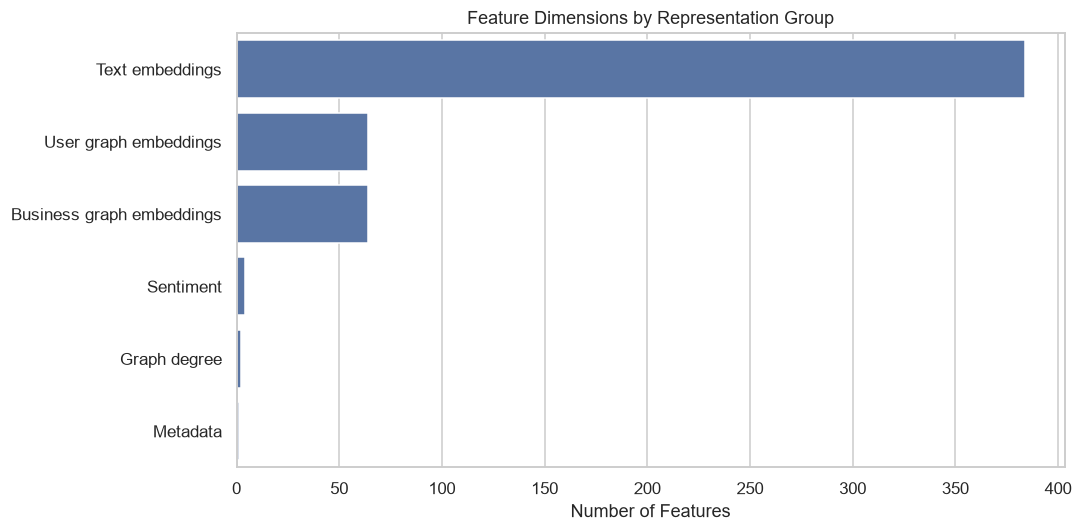

In [24]:
feature_groups = pd.DataFrame({
    "group": ["Text embeddings", "User graph embeddings", "Business graph embeddings", "Sentiment", "Graph degree", "Metadata"],
    "dimensions": [
        len(text_emb_cols),
        len([c for c in feature_names if c.startswith("u_ge_")]),
        len([c for c in feature_names if c.startswith("b_ge_")]),
        len([c for c in feature_names if c.startswith("vader_")]),
        len([c for c in feature_names if c in ["user_deg", "biz_deg"]]),
        len([c for c in feature_names if not (c.startswith("text_emb_") or c.startswith("u_ge_") or c.startswith("b_ge_") or c.startswith("vader_")) and c not in ["user_deg", "biz_deg"]])
    ]
})
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=feature_groups, y="group", x="dimensions", ax=ax)
ax.set_title("Feature Dimensions by Representation Group")
ax.set_xlabel("Number of Features")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 20. Splitting Data into Group-Disjoint Train, Validation, and Test Sets

In [25]:
gss_outer = GroupShuffleSplit(n_splits=1, test_size=0.40, random_state=SEED)
train_idx, temp_idx = next(gss_outer.split(X, y, groups=sample_df["user_id"]))
gss_inner = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_rel_idx, test_rel_idx = next(gss_inner.split(X[temp_idx], y[temp_idx], groups=sample_df["user_id"].iloc[temp_idx].values))
val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

train_users = set(sample_df["user_id"].iloc[train_idx])
val_users = set(sample_df["user_id"].iloc[val_idx])
test_users = set(sample_df["user_id"].iloc[test_idx])
assert len(train_users & val_users) == 0, "User overlap train/val"
assert len(train_users & test_users) == 0, "User overlap train/test"
assert len(val_users & test_users) == 0, "User overlap val/test"

X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
groups_train = sample_df["user_id"].iloc[train_idx].values
groups_val = sample_df["user_id"].iloc[val_idx].values
groups_test = sample_df["user_id"].iloc[test_idx].values

logger.info("Split sizes (group-disjoint by user_id): train=%d val=%d test=%d",
            len(train_idx), len(val_idx), len(test_idx))
logger.info("Class balance - train pos=%.3f val pos=%.3f test pos=%.3f",
            y_train.mean(), y_val.mean(), y_test.mean())

gss_outer_b = GroupShuffleSplit(n_splits=1, test_size=0.40, random_state=SEED)
train_idx_b, temp_idx_b = next(gss_outer_b.split(X, y, groups=sample_df["business_id"]))
gss_inner_b = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_rel_b, test_rel_b = next(gss_inner_b.split(X[temp_idx_b], y[temp_idx_b], groups=sample_df["business_id"].iloc[temp_idx_b].values))
val_idx_b = temp_idx_b[val_rel_b]
test_idx_b = temp_idx_b[test_rel_b]
train_biz = set(sample_df["business_id"].iloc[train_idx_b])
val_biz = set(sample_df["business_id"].iloc[val_idx_b])
test_biz = set(sample_df["business_id"].iloc[test_idx_b])
assert len(train_biz & val_biz) == 0 and len(train_biz & test_biz) == 0 and len(val_biz & test_biz) == 0
logger.info("Secondary business-disjoint split prepared: train=%d val=%d test=%d",
            len(train_idx_b), len(val_idx_b), len(test_idx_b))

00:15:18 | INFO | Split sizes (group-disjoint by user_id): train=11992 val=4011 test=3997
00:15:18 | INFO | Class balance - train pos=0.116 val pos=0.120 test pos=0.106
00:15:18 | INFO | Secondary business-disjoint split prepared: train=11915 val=4040 test=4045


## 21. Balancing the Training Dataset Before Model Tuning

Class balancing is performed only after the group-disjoint train/validation/test split.
Validation and test sets are never oversampled.

The three strategies compared here are:
1. None: original training distribution.
2. scale_pos_weight: cost-sensitive XGBoost training.
3. SMOTE: synthetic minority oversampling on the training set only.

Threshold tuning is kept separate because it changes the decision threshold; it does not rebalance the dataset.

In [26]:
scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

scale_pos_weight_value = float((y_train == 0).sum() / max(1, (y_train == 1).sum()))

baseline_params = dict(
    n_estimators=200, max_depth=6, learning_rate=0.05,
    subsample=0.85, colsample_bytree=0.7,
    reg_lambda=1.5, reg_alpha=0.5,
    objective="binary:logistic", tree_method="hist",
    n_jobs=2, random_state=SEED, eval_metric="aucpr",
    early_stopping_rounds=CONFIG["EARLY_STOP"])

strategies = {}

m_none = xgb.XGBClassifier(**baseline_params)
m_none.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=False)
pr_none = average_precision_score(y_val, m_none.predict_proba(X_val_scaled)[:, 1])
strategies["none"] = {"pr_auc": pr_none, "model": m_none}

m_spw = xgb.XGBClassifier(**baseline_params, scale_pos_weight=scale_pos_weight_value)
m_spw.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=False)
pr_spw = average_precision_score(y_val, m_spw.predict_proba(X_val_scaled)[:, 1])
strategies["scale_pos_weight"] = {"pr_auc": pr_spw, "model": m_spw}

smote = SMOTE(random_state=SEED)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)

m_smote = xgb.XGBClassifier(**baseline_params)
m_smote.fit(X_train_sm, y_train_sm, eval_set=[(X_val_scaled, y_val)], verbose=False)
pr_smote = average_precision_score(y_val, m_smote.predict_proba(X_val_scaled)[:, 1])
strategies["smote"] = {"pr_auc": pr_smote, "model": m_smote}

balancing_df = (
    pd.DataFrame([
        {
            "strategy": name,
            "train_rows": len(y_train_sm) if name == "smote" else len(y_train),
            "train_positive_rate": float(y_train_sm.mean()) if name == "smote" else float(y_train.mean()),
            "val_pr_auc": result["pr_auc"]
        }
        for name, result in strategies.items()
    ])
    .sort_values("val_pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(balancing_df)
best_strategy_name = balancing_df.iloc[0]["strategy"]
logger.info("Selected training strategy: %s", best_strategy_name)

,strategy,train_rows,train_positive_rate,val_pr_auc
0,none,11992,0.116494,0.695898
1,scale_pos_weight,11992,0.116494,0.675850
2,smote,21190,0.500000,0.657435


00:16:16 | INFO | Selected training strategy: none


### Visualization: Class-Balancing Strategy Comparison

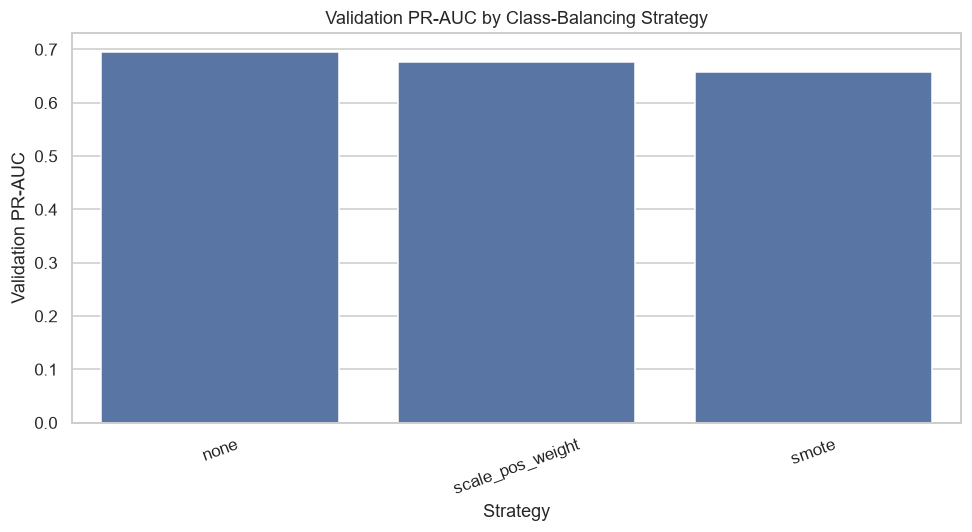

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=balancing_df, x="strategy", y="val_pr_auc", ax=ax)
ax.set_title("Validation PR-AUC by Class-Balancing Strategy")
ax.set_xlabel("Strategy")
ax.set_ylabel("Validation PR-AUC")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 22. Tuning Hyperparameters with Optuna

In [28]:
t0 = time.perf_counter()
def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 400),
        max_depth=trial.suggest_int("max_depth", 3, 9),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 0.0, 5.0),
        reg_alpha=trial.suggest_float("reg_alpha", 0.0, 5.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        objective="binary:logistic", tree_method="hist",
        n_jobs=2, random_state=SEED, eval_metric="aucpr",
        early_stopping_rounds=CONFIG["EARLY_STOP"]
    )
    if best_strategy_name == "scale_pos_weight":
        params["scale_pos_weight"] = scale_pos_weight_value
    model = xgb.XGBClassifier(**params)
    if best_strategy_name == "smote":
        model.fit(X_train_sm, y_train_sm, eval_set=[(X_val_scaled, y_val)], verbose=False)
    else:
        model.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=False)
    proba = model.predict_proba(X_val_scaled)[:, 1]
    return average_precision_score(y_val, proba)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=CONFIG["OPTUNA_TRIALS"], show_progress_bar=False)
best_params = study.best_params
best_params.update(dict(
    objective="binary:logistic", tree_method="hist",
    n_jobs=2, random_state=SEED, eval_metric="aucpr",
    early_stopping_rounds=CONFIG["EARLY_STOP"]
))
if best_strategy_name == "scale_pos_weight":
    best_params["scale_pos_weight"] = scale_pos_weight_value

TIMING["optuna"] = time.perf_counter() - t0
logger.info("Optuna finished in %.1fs | best val PR-AUC: %.4f", TIMING["optuna"], study.best_value)
logger.info("Best params:")
for k, v in best_params.items():
    logger.info("  %s = %s", k, v)

00:21:35 | INFO | Optuna finished in 317.9s | best val PR-AUC: 0.7102
00:21:35 | INFO | Best params:
00:21:35 | INFO |   n_estimators = 280
00:21:35 | INFO |   max_depth = 7
00:21:35 | INFO |   learning_rate = 0.010725209743171996
00:21:35 | INFO |   subsample = 0.9849549260809971
00:21:35 | INFO |   colsample_bytree = 0.899465584480253
00:21:35 | INFO |   reg_lambda = 1.0616955533913808
00:21:35 | INFO |   reg_alpha = 0.9091248360355031
00:21:35 | INFO |   min_child_weight = 2
00:21:35 | INFO |   objective = binary:logistic
00:21:35 | INFO |   tree_method = hist
00:21:35 | INFO |   n_jobs = 2
00:21:35 | INFO |   random_state = 42
00:21:35 | INFO |   eval_metric = aucpr
00:21:35 | INFO |   early_stopping_rounds = 25


## 23. Training the Feature-Fusion Classifier

In [29]:
t0 = time.perf_counter()
fusion_model = xgb.XGBClassifier(**best_params)

if best_strategy_name == "smote":
    fusion_model.fit(X_train_sm, y_train_sm, eval_set=[(X_val_scaled, y_val)], verbose=False)
else:
    fusion_model.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=False)

TIMING["fusion_train"] = time.perf_counter() - t0
decision_threshold = 0.5

logger.info(
    "Feature-fusion classifier trained in %.1fs | best_iter=%d | threshold=%.3f",
    TIMING["fusion_train"], fusion_model.best_iteration, decision_threshold
)
logger.info(
    "Architecture: feature-fusion model (Sentence-Transformer + Node2Vec + VADER + metadata), NOT a GNN."
)

00:22:28 | INFO | Feature-fusion classifier trained in 52.4s | best_iter=279 | threshold=0.500
00:22:28 | INFO | Architecture: feature-fusion model (Sentence-Transformer + Node2Vec + VADER + metadata), NOT a GNN.


### Visualization: Training Performance

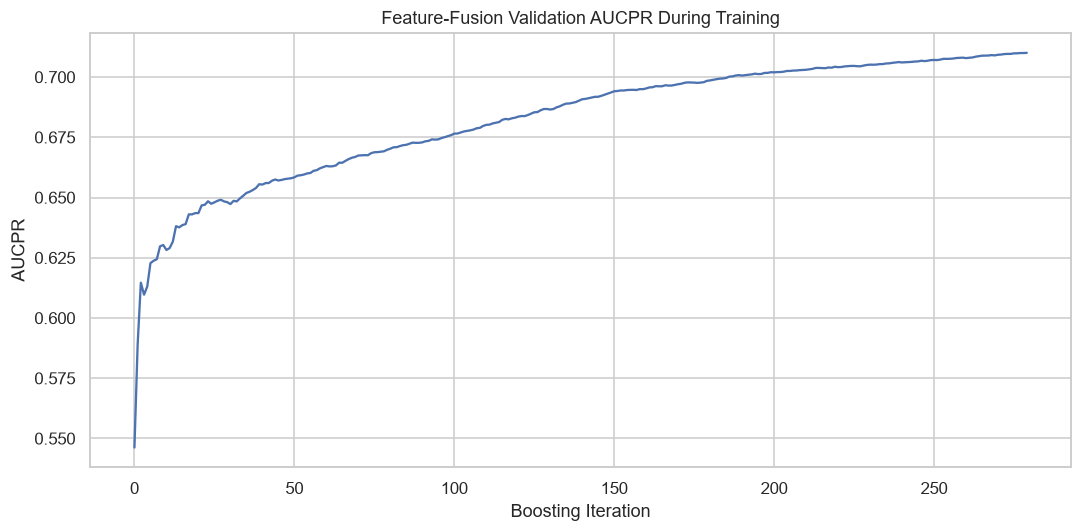

In [30]:
evals = fusion_model.evals_result()
eval_key = next(iter(evals)) if evals else None
if eval_key is not None:
    metric_key = next(iter(evals[eval_key]))
    history = pd.DataFrame({"iteration": np.arange(len(evals[eval_key][metric_key])), metric_key: evals[eval_key][metric_key]})
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(history["iteration"], history[metric_key])
    ax.set_title(f"Feature-Fusion Validation {metric_key.upper()} During Training")
    ax.set_xlabel("Boosting Iteration")
    ax.set_ylabel(metric_key.upper())
    plt.tight_layout()
    plt.show()

## 24. Training the Graph Neural Network Baseline

In [31]:
t0 = time.perf_counter()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_review_edge_index(indices):
    idx = np.asarray(indices)
    sub = sample_df.iloc[idx][["user_id", "business_id", "date"]].copy().reset_index(drop=True)
    sub["_local_idx"] = np.arange(len(sub), dtype=np.int64)
    edge_pairs = []
    for col in ["user_id", "business_id"]:
        ordered = sub.sort_values([col, "date", "_local_idx"], kind="mergesort")
        for _, grp in ordered.groupby(col, sort=False):
            nodes = grp["_local_idx"].to_numpy(dtype=np.int64)
            if len(nodes) > 1:
                a, b = nodes[:-1], nodes[1:]
                edge_pairs.extend(zip(a, b))
                edge_pairs.extend(zip(b, a))
    if not edge_pairs:
        edge_index = np.vstack([np.arange(len(sub)), np.arange(len(sub))])
    else:
        edge_index = np.asarray(edge_pairs, dtype=np.int64).T
    return torch.tensor(edge_index, dtype=torch.long, device=device)

class FallbackSAGEConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim * 2, out_dim)

    def forward(self, x, edge_index):
        src, dst = edge_index
        neigh = torch.zeros_like(x)
        deg = torch.zeros(x.size(0), device=x.device, dtype=x.dtype)
        neigh.index_add_(0, dst, x[src])
        deg.index_add_(0, dst, torch.ones_like(dst, dtype=x.dtype))
        neigh = neigh / deg.clamp_min(1.0).unsqueeze(1)
        return self.lin(torch.cat([x, neigh], dim=1))

class GraphSAGEBaseline(nn.Module):
    def __init__(self, in_dim, hidden, out_dim=1):
        super().__init__()
        Conv = SAGEConv if PYG_AVAILABLE else FallbackSAGEConv
        self.conv1 = Conv(in_dim, hidden)
        self.conv2 = Conv(hidden, hidden)
        self.head = nn.Linear(hidden, out_dim)

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        h = F.dropout(h, p=0.2, training=self.training)
        h = F.relu(self.conv2(h, edge_index))
        return self.head(h).squeeze(-1)

def train_graphsage(X_tr, y_tr, tr_indices, X_eval, y_eval, eval_indices, epochs=None):
    epochs = epochs or CONFIG["GNN_EPOCHS"]
    model = GraphSAGEBaseline(X_tr.shape[1], CONFIG["GNN_HIDDEN"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["GNN_LR"])
    criterion = nn.BCEWithLogitsLoss()

    x_tr = torch.tensor(np.asarray(X_tr), dtype=torch.float32, device=device)
    y_tr = torch.tensor(np.asarray(y_tr), dtype=torch.float32, device=device)
    x_ev = torch.tensor(np.asarray(X_eval), dtype=torch.float32, device=device)
    edge_tr = build_review_edge_index(tr_indices)
    edge_ev = build_review_edge_index(eval_indices)

    best_val_pr = -np.inf
    best_state = None
    val_history = []
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        logits = model(x_tr, edge_tr)
        loss = criterion(logits, y_tr)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_proba = torch.sigmoid(model(x_ev, edge_ev)).cpu().numpy()
        val_pr = average_precision_score(y_eval, val_proba)
        val_history.append(val_pr)
        if val_pr > best_val_pr:
            best_val_pr = val_pr
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    global gnn_training_history
    gnn_training_history = val_history
    return model, best_val_pr

gnn_model, best_val_pr = train_graphsage(
    X_train_scaled, y_train, train_idx,
    X_val_scaled, y_val, val_idx
)
with torch.no_grad():
    x_test = torch.tensor(np.asarray(X_test_scaled), dtype=torch.float32, device=device)
    edge_test = build_review_edge_index(test_idx)
    gnn_test_proba = torch.sigmoid(gnn_model(x_test, edge_test)).cpu().numpy()

TIMING["gnn_train"] = time.perf_counter() - t0
logger.info("GNN baseline (GraphSAGE) trained in %.1fs | best val PR-AUC: %.4f | PyG=%s",
            TIMING["gnn_train"], best_val_pr, PYG_AVAILABLE)

00:22:49 | INFO | GNN baseline (GraphSAGE) trained in 18.3s | best val PR-AUC: 0.2842 | PyG=True


### Visualization: GraphSAGE Training Comparison

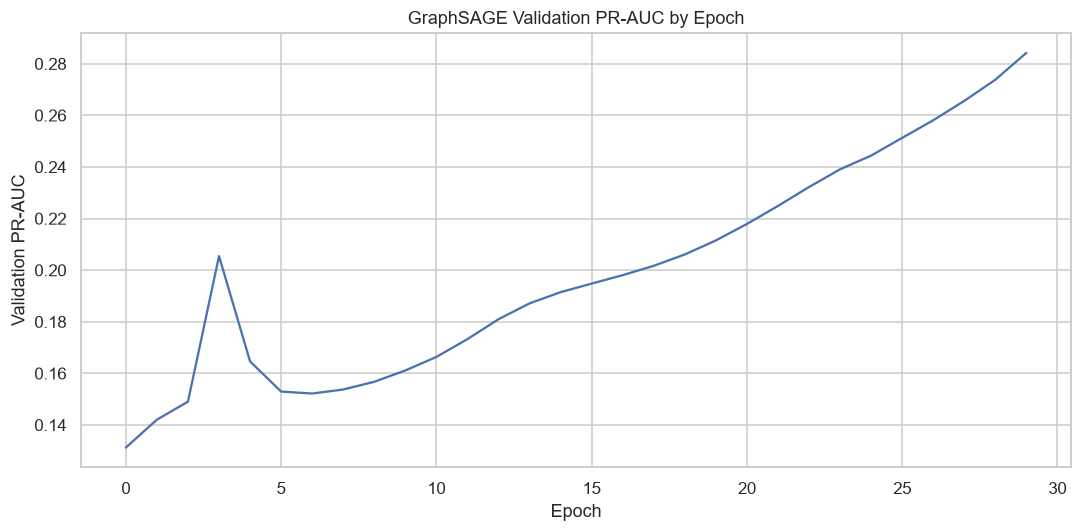

In [32]:
gnn_history = pd.DataFrame({"epoch": np.arange(len(gnn_training_history)), "val_pr_auc": gnn_training_history}) if "gnn_training_history" in globals() else pd.DataFrame()
if len(gnn_history):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(gnn_history["epoch"], gnn_history["val_pr_auc"])
    ax.set_title("GraphSAGE Validation PR-AUC by Epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation PR-AUC")
    plt.tight_layout()
    plt.show()

## 25. Evaluating with Grouped Cross-Validation and Confidence Intervals

In [33]:
def bootstrap_metric_ci(y_true, y_proba, metric_fn, n=500, alpha=0.05, seed=SEED):
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)
    rng = np.random.RandomState(seed)
    scores = []
    for _ in range(n):
        idx = rng.randint(0, len(y_true), size=len(y_true))
        y_b = y_true[idx]
        p_b = y_proba[idx]
        if len(np.unique(y_b)) < 2:
            continue
        try:
            scores.append(metric_fn(y_b, p_b))
        except ValueError:
            continue
    if not scores:
        return (np.nan, np.nan)
    return (float(np.percentile(scores, 100 * alpha / 2)),
            float(np.percentile(scores, 100 * (1 - alpha / 2))))

def compute_metrics(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
        "mcc": matthews_corrcoef(y_true, y_pred)
    }

test_proba_fusion = fusion_model.predict_proba(X_test_scaled)[:, 1]
test_pred_fusion = (test_proba_fusion >= decision_threshold).astype(int)
fusion_test_metrics = compute_metrics(y_test, test_pred_fusion, test_proba_fusion)
gnn_test_pred = (gnn_test_proba >= 0.5).astype(int)
gnn_test_metrics = compute_metrics(y_test, gnn_test_pred, gnn_test_proba)

sgkf = StratifiedGroupKFold(n_splits=CONFIG["N_FOLDS"], shuffle=True, random_state=SEED)
fold_records = []
for fold_id, (tr_idx, te_idx) in enumerate(sgkf.split(X, y, groups=sample_df["user_id"].values), start=1):
    Xf_tr, Xf_te = X[tr_idx], X[te_idx]
    yf_tr, yf_te = y[tr_idx], y[te_idx]
    sc = StandardScaler(with_mean=False)
    Xf_tr_s = sc.fit_transform(Xf_tr)
    Xf_te_s = sc.transform(Xf_te)
    if best_strategy_name == "smote":
        Xf_tr_s, yf_tr = SMOTE(random_state=SEED).fit_resample(Xf_tr_s, yf_tr)

    m = xgb.XGBClassifier(**best_params)
    m.fit(Xf_tr_s, yf_tr, eval_set=[(Xf_te_s, yf_te)], verbose=False)
    proba = m.predict_proba(Xf_te_s)[:, 1]
    pred = (proba >= 0.5).astype(int)
    fold_records.append({"fold": fold_id, "model": "feature_fusion", **compute_metrics(yf_te, pred, proba)})

    mt, _ = train_graphsage(Xf_tr_s, yf_tr, tr_idx, Xf_te_s, yf_te, te_idx)
    mt.eval()
    with torch.no_grad():
        xte = torch.tensor(np.asarray(Xf_te_s), dtype=torch.float32, device=device)
        edge_te = build_review_edge_index(te_idx)
        pr_proba = torch.sigmoid(mt(xte, edge_te)).cpu().numpy()
    pr_pred = (pr_proba >= 0.5).astype(int)
    fold_records.append({"fold": fold_id, "model": "graph_sage", **compute_metrics(yf_te, pr_pred, pr_proba)})

fold_df = pd.DataFrame(fold_records)
agg_df = fold_df.groupby("model").agg(["mean", "std"]).round(4)
display(agg_df)

fusion_pr = fold_df.loc[fold_df["model"] == "feature_fusion", "pr_auc"].values
gnn_pr = fold_df.loc[fold_df["model"] == "graph_sage", "pr_auc"].values
if wilcoxon is not None and len(fusion_pr) == len(gnn_pr) and len(fusion_pr) >= 3:
    stat, p_val = wilcoxon(fusion_pr, gnn_pr)
    logger.info("Paired Wilcoxon signed-rank test on fold PR-AUC: stat=%.4f p=%.4g", stat, p_val)
else:
    p_val = np.nan
    logger.info("Wilcoxon test skipped (requires equal paired folds and at least 3 folds).")

bootstrap_fusion_pr = bootstrap_metric_ci(y_test, test_proba_fusion, average_precision_score, n=CONFIG["BOOTSTRAP_N"])
bootstrap_fusion_roc = bootstrap_metric_ci(y_test, test_proba_fusion, roc_auc_score, n=CONFIG["BOOTSTRAP_N"])
bootstrap_gnn_pr = bootstrap_metric_ci(y_test, gnn_test_proba, average_precision_score, n=CONFIG["BOOTSTRAP_N"])
bootstrap_gnn_roc = bootstrap_metric_ci(y_test, gnn_test_proba, roc_auc_score, n=CONFIG["BOOTSTRAP_N"])

test_summary = pd.DataFrame([
    {"model": "feature_fusion", **fusion_test_metrics,
     "pr_auc_ci_low": bootstrap_fusion_pr[0], "pr_auc_ci_high": bootstrap_fusion_pr[1],
     "roc_auc_ci_low": bootstrap_fusion_roc[0], "roc_auc_ci_high": bootstrap_fusion_roc[1]},
    {"model": "graph_sage", **gnn_test_metrics,
     "pr_auc_ci_low": bootstrap_gnn_pr[0], "pr_auc_ci_high": bootstrap_gnn_pr[1],
     "roc_auc_ci_low": bootstrap_gnn_roc[0], "roc_auc_ci_high": bootstrap_gnn_roc[1]},
])
display(test_summary.round(4))
logger.info("Wilcoxon p-value (feature_fusion vs graph_sage): %.4g", p_val)

fold      accuracy         precision          recall          \
               mean  std     mean     std      mean     std    mean     std   
model                                                                         
feature_fusion  2.0  1.0   0.9315  0.0045    0.9269  0.0219  0.4388  0.0026   
graph_sage      2.0  1.0   0.8851  0.0069    0.2222  0.3849  0.0019  0.0032   

                    f1         roc_auc          pr_auc             mcc          
                  mean     std    mean     std    mean     std    mean     std  
model                                                                           
feature_fusion  0.5956  0.0059  0.8896  0.0084  0.7110  0.0093  0.6106  0.0103  
graph_sage      0.0037  0.0064  0.7427  0.0149  0.2924  0.0378  0.0181  0.0314

00:26:38 | INFO | Paired Wilcoxon signed-rank test on fold PR-AUC: stat=0.0000 p=0.25


,model,accuracy,precision,recall,f1,roc_auc,pr_auc,mcc,pr_auc_ci_low,pr_auc_ci_high,roc_auc_ci_low,roc_auc_ci_high
0,feature_fusion,0.9327,0.8844,0.4171,0.5668,0.8871,0.6902,0.5801,0.6460,0.7327,0.8672,0.9049
1,graph_sage,0.8944,0.0000,0.0000,0.0000,0.7505,0.2709,0.0000,0.2359,0.3097,0.7246,0.7721


00:26:41 | INFO | Wilcoxon p-value (feature_fusion vs graph_sage): 0.25


### Visualization: Model Performance on the Test Set

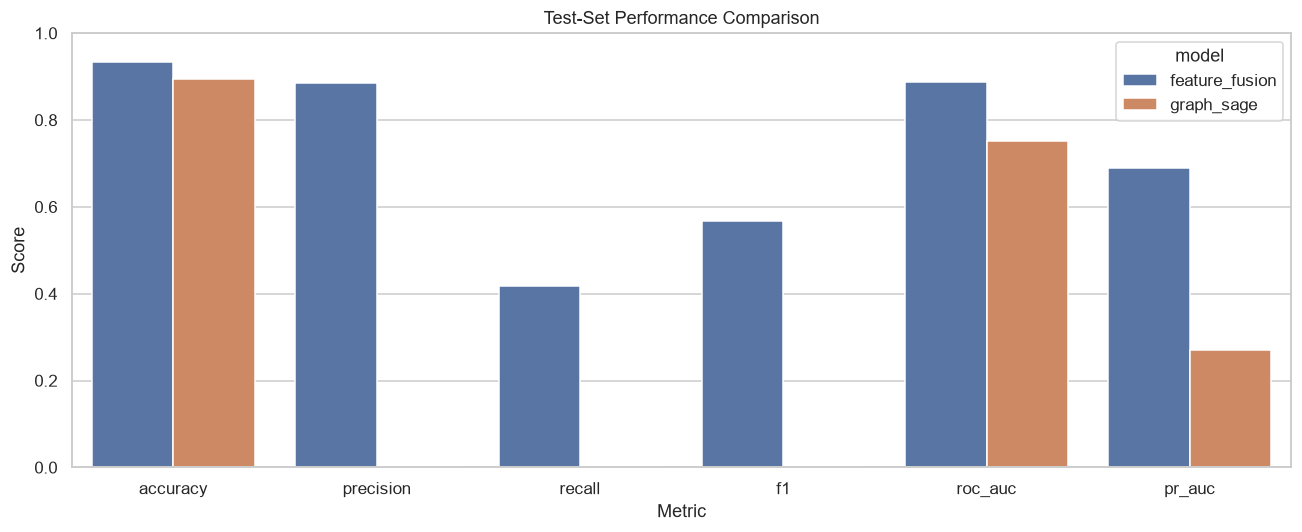

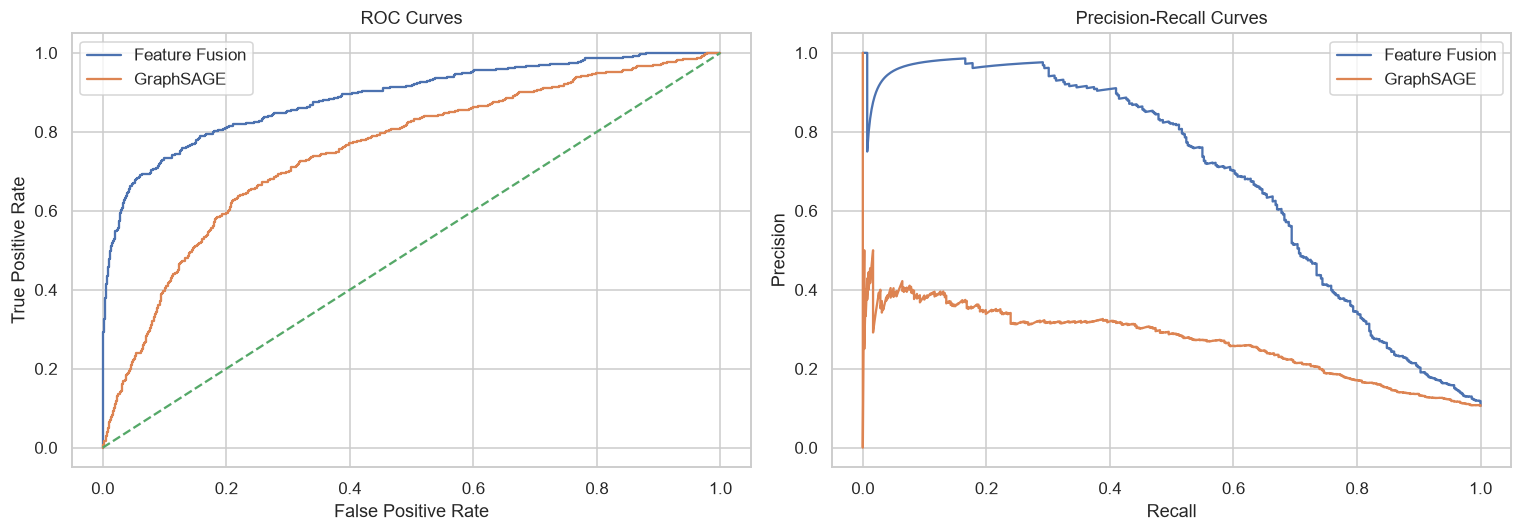

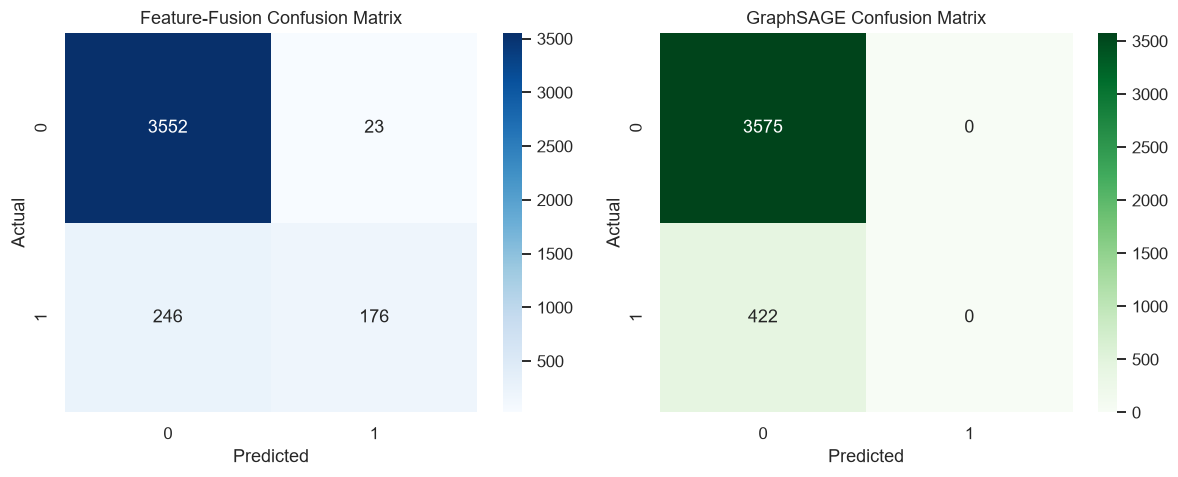

In [34]:
metric_plot_df = test_summary.melt(id_vars="model", value_vars=["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"], var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=metric_plot_df, x="metric", y="score", hue="model", ax=ax)
ax.set_title("Test-Set Performance Comparison")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, proba in [("Feature Fusion", test_proba_fusion), ("GraphSAGE", gnn_test_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=name)
    precision, recall, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], linestyle="--")
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_fusion = confusion_matrix(y_test, test_pred_fusion)
cm_gnn = confusion_matrix(y_test, gnn_test_pred)
sns.heatmap(cm_fusion, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Feature-Fusion Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
sns.heatmap(cm_gnn, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("GraphSAGE Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 26. Performing Error Analysis

00:26:42 | INFO | False positives: 23 | False negatives: 246
00:26:42 | INFO | Sample false positives (text, stars, length):


,text,stars,text_len,proba
286,I had just eaten there for the first time toda...,1.0,458,0.682566
438,Came here with a party of 10. \nThe waitress o...,1.0,262,0.699823
474,Came here to eat and started asking questions ...,1.0,259,0.587464
893,"Look, I don't know what the jiggly, opaque, do...",1.0,144,0.657894
1132,absolutely horrible customer experience. roach...,1.0,595,0.625477
1253,I had been told by a couple friends this place...,1.0,671,0.504362
1363,Worst brunch ever! \n\nThe first meal I ordere...,1.0,551,0.642869
1478,Horrible service and I was served an actual ra...,1.0,497,0.601618
1655,"My first experience a year ago, at Nauti Nancy...",1.0,2081,0.704242
2192,Do not get the Spanish omelette; it is a jar o...,1.0,334,0.503908


00:26:42 | INFO | Sample false negatives (text, stars, length):


,text,stars,text_len,proba
38,"This location is new, but must admit totally u...",1.0,356,0.412701
43,"Sean G. was very prompt, friendly and courteou...",5.0,241,0.357434
62,Good experience. Deep dish pizza was fantastic...,4.0,239,0.024333
127,Great place to meet friends and just drink it ...,5.0,167,0.070057
145,I have lived here for 20 years and have been t...,5.0,434,0.051819
156,I've been going to Pritchett Eye Care Associat...,1.0,765,0.267697
169,I have had nothing but positive interactions w...,4.0,227,0.045106
174,I was excited to get my enchiladas that were f...,2.0,400,0.274959
239,We tried the cupcakes for a birthday party. I ...,1.0,324,0.479485
249,"Previously, the service we've recieved was abo...",2.0,493,0.374863


00:26:43 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:26:43 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


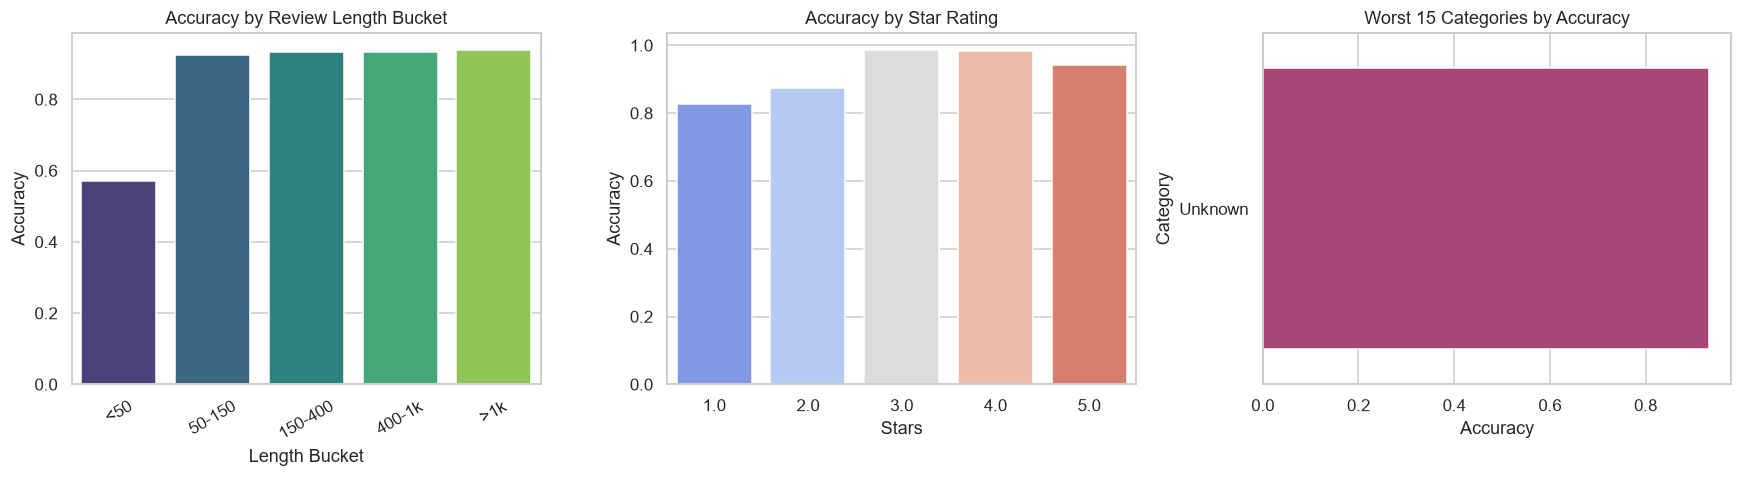

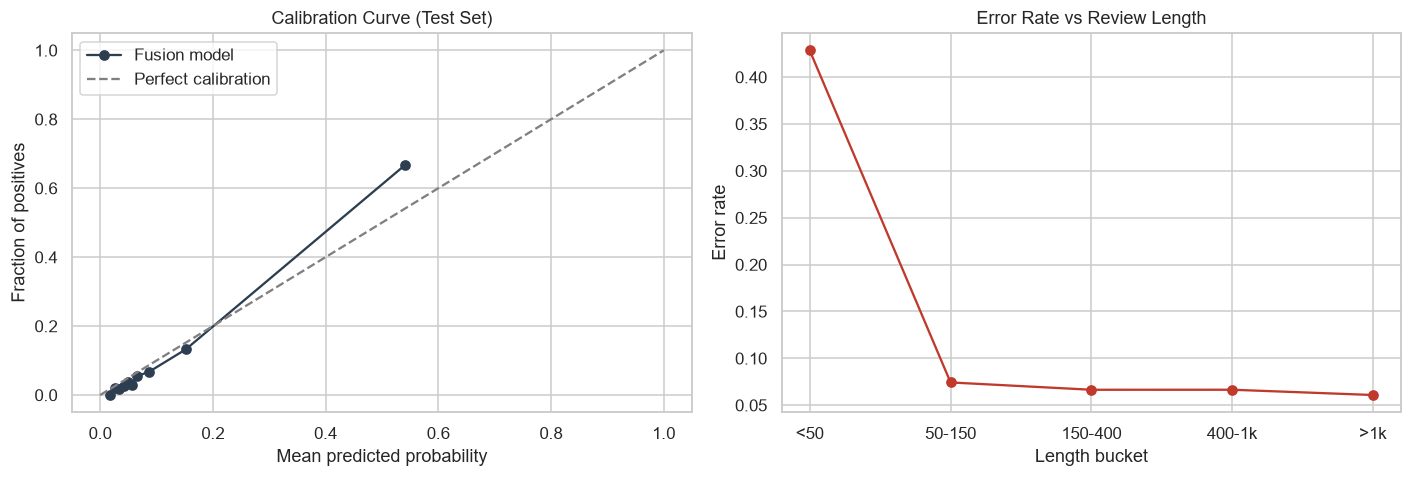

In [35]:
fp_mask = (test_pred_fusion == 1) & (y_test == 0)
fn_mask = (test_pred_fusion == 0) & (y_test == 1)
fp_idx = np.where(fp_mask)[0]
fn_idx = np.where(fn_mask)[0]
logger.info("False positives: %d | False negatives: %d", len(fp_idx), len(fn_idx))

test_rows = sample_df.iloc[test_idx].reset_index(drop=True).copy()
test_rows["pred"] = test_pred_fusion
test_rows["proba"] = test_proba_fusion
test_rows["true"] = y_test
test_rows["len_bucket"] = pd.cut(test_rows["clean_text_lower"].str.len(),
                                 bins=[0, 50, 150, 400, 1000, 100000],
                                 labels=["<50", "50-150", "150-400", "400-1k", ">1k"])

fp_examples = test_rows[test_rows["pred"].eq(1) & test_rows["true"].eq(0)].head(20)
fn_examples = test_rows[test_rows["pred"].eq(0) & test_rows["true"].eq(1)].head(20)
logger.info("Sample false positives (text, stars, length):")
display(fp_examples[["text", "stars", "text_len", "proba"]].head(20))
logger.info("Sample false negatives (text, stars, length):")
display(fn_examples[["text", "stars", "text_len", "proba"]].head(20))

test_rows["correct"] = (test_rows["pred"] == test_rows["true"]).astype(int)
err_by_len = test_rows.groupby("len_bucket", observed=True)["correct"].mean().reset_index()
err_by_star = test_rows.groupby("stars")["correct"].mean().reset_index()
biz_cat_map = business_df.set_index("business_id")["categories"].to_dict()
test_rows["category"] = test_rows["business_id"].map(biz_cat_map).fillna("Unknown")
err_by_cat = (test_rows.assign(category=test_rows["category"].str.split(",").str[0])
              .groupby("category")["correct"].mean().sort_values().head(15).reset_index())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(data=err_by_len, x="len_bucket", y="correct", ax=axes[0], palette="viridis")
axes[0].set_title("Accuracy by Review Length Bucket")
axes[0].set_xlabel("Length Bucket"); axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=30)
sns.barplot(data=err_by_star, x="stars", y="correct", ax=axes[1], palette="coolwarm")
axes[1].set_title("Accuracy by Star Rating")
axes[1].set_xlabel("Stars"); axes[1].set_ylabel("Accuracy")
sns.barplot(data=err_by_cat, y="category", x="correct", ax=axes[2], palette="magma")
axes[2].set_title("Worst 15 Categories by Accuracy")
axes[2].set_xlabel("Accuracy"); axes[2].set_ylabel("Category")
plt.tight_layout(); plt.show()

prob_true, prob_pred = calibration_curve(y_test, test_proba_fusion, n_bins=10, strategy="quantile")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(prob_pred, prob_true, marker="o", color="#2c3e50", label="Fusion model")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
axes[0].set_title("Calibration Curve (Test Set)")
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Fraction of positives")
axes[0].legend()
axes[1].plot(err_by_len["len_bucket"].astype(str), 1 - err_by_len["correct"],
             marker="o", color="#c0392b")
axes[1].set_title("Error Rate vs Review Length")
axes[1].set_xlabel("Length bucket")
axes[1].set_ylabel("Error rate")
plt.tight_layout(); plt.show()

### Visualization: Error Analysis

00:26:43 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
00:26:43 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


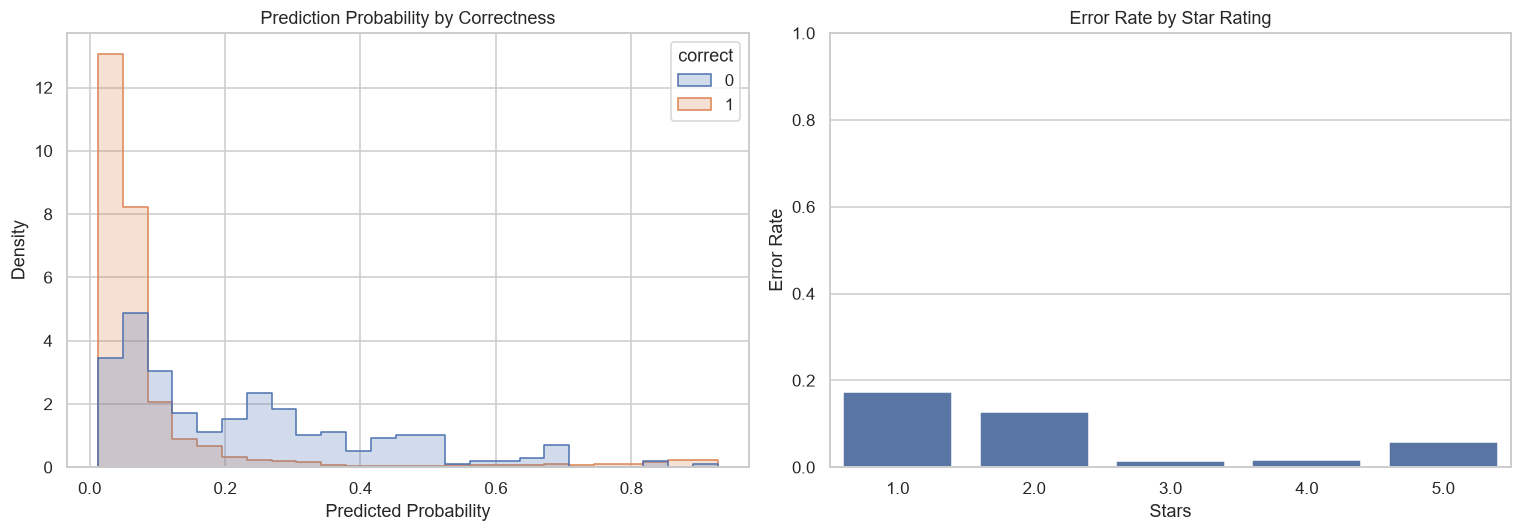

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=test_rows, x="proba", hue="correct", bins=25, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Prediction Probability by Correctness")
axes[0].set_xlabel("Predicted Probability")
axes[0].set_ylabel("Density")
error_rate_by_star = test_rows.assign(error=(test_rows["pred"] != test_rows["true"]).astype(int)).groupby("stars")["error"].mean().reset_index()
sns.barplot(data=error_rate_by_star, x="stars", y="error", ax=axes[1])
axes[1].set_title("Error Rate by Star Rating")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Error Rate")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 27. Generating SHAP Explanations

00:26:52 | INFO | SHAP value matrix: (1500, 519) (took 7.8s)


,feature,mean_abs_shap
0,stars,0.957892
1,biz_deg,0.219455
2,user_deg,0.190897
3,b_ge_2,0.033956
4,text_emb_14,0.032345
5,vader_compound,0.028366
6,text_emb_11,0.026922
7,text_emb_233,0.020678
8,text_emb_354,0.020275
9,text_emb_319,0.019096


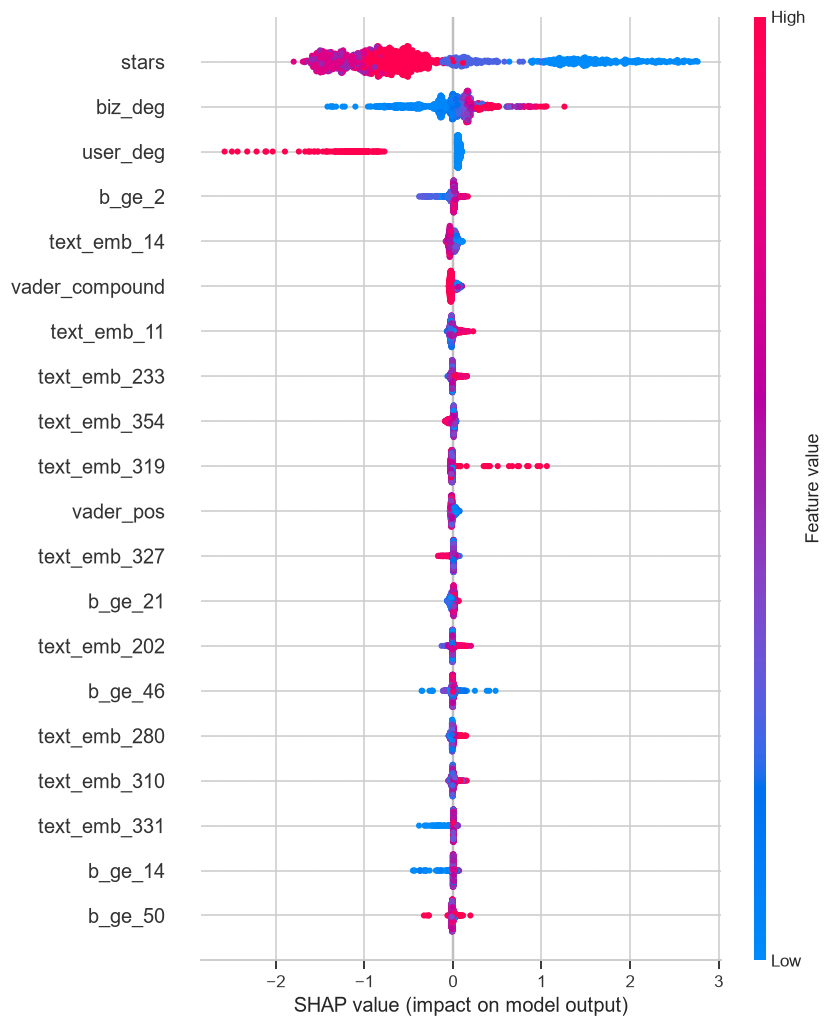

00:26:52 | INFO | Inspecting 6 reviews (3 highest proba fake, 3 highest proba genuine):
00:26:52 | INFO | [0] proba=0.923 true=1 stars=1 len=664


text    Food was good and safety protocols were perfec...
Name: 1138, dtype: object

00:26:52 | INFO | [1] proba=0.924 true=1 stars=1 len=717


text    A group of us went there for dinner and we mad...
Name: 9432, dtype: object

00:26:52 | INFO | [2] proba=0.928 true=1 stars=1 len=253


...

text    I was excited to check this place out. I have ...
Name: 8561, dtype: object

00:26:52 | INFO | [4] proba=0.013 true=0 stars=3 len=879


text    The food was alright but nothing to rave about...
Name: 12150, dtype: object

00:26:52 | INFO | [5] proba=0.013 true=0 stars=4 len=712


text    At first this place looks kind of intimidating...
Name: 5626, dtype: object

In [37]:
t0 = time.perf_counter()
explainer = shap.TreeExplainer(fusion_model)
shap_sample = X_test_scaled[:min(1500, len(X_test_scaled))]
shap_values = np.asarray(explainer.shap_values(shap_sample))
if shap_values.ndim == 3:
    shap_values = shap_values[..., -1]
TIMING["shap"] = time.perf_counter() - t0
logger.info("SHAP value matrix: %s (took %.1fs)", shap_values.shape, TIMING["shap"])

global_imp = np.abs(shap_values).mean(axis=0)
imp_df = (pd.DataFrame({"feature": feature_names, "mean_abs_shap": global_imp})
          .sort_values("mean_abs_shap", ascending=False).head(25)
          .reset_index(drop=True))
display(imp_df)

shap.summary_plot(shap_values, shap_sample,
                  feature_names=feature_names, max_display=20,
                  show=True, color_bar=True, plot_type="dot")

interesting_idx = np.argsort(test_proba_fusion)[-3:].tolist() + np.argsort(test_proba_fusion)[:3].tolist()
logger.info("Inspecting 6 reviews (3 highest proba fake, 3 highest proba genuine):")
for i, idx in enumerate(interesting_idx):
    row = sample_df.iloc[test_idx[idx]]
    logger.info("[%d] proba=%.3f true=%d stars=%d len=%d",
                i, test_proba_fusion[idx], int(y_test[idx]), int(row["stars"]), int(row["text_len"]))
    display(row[["text"]].head(1))

### Visualization: Global SHAP Importance

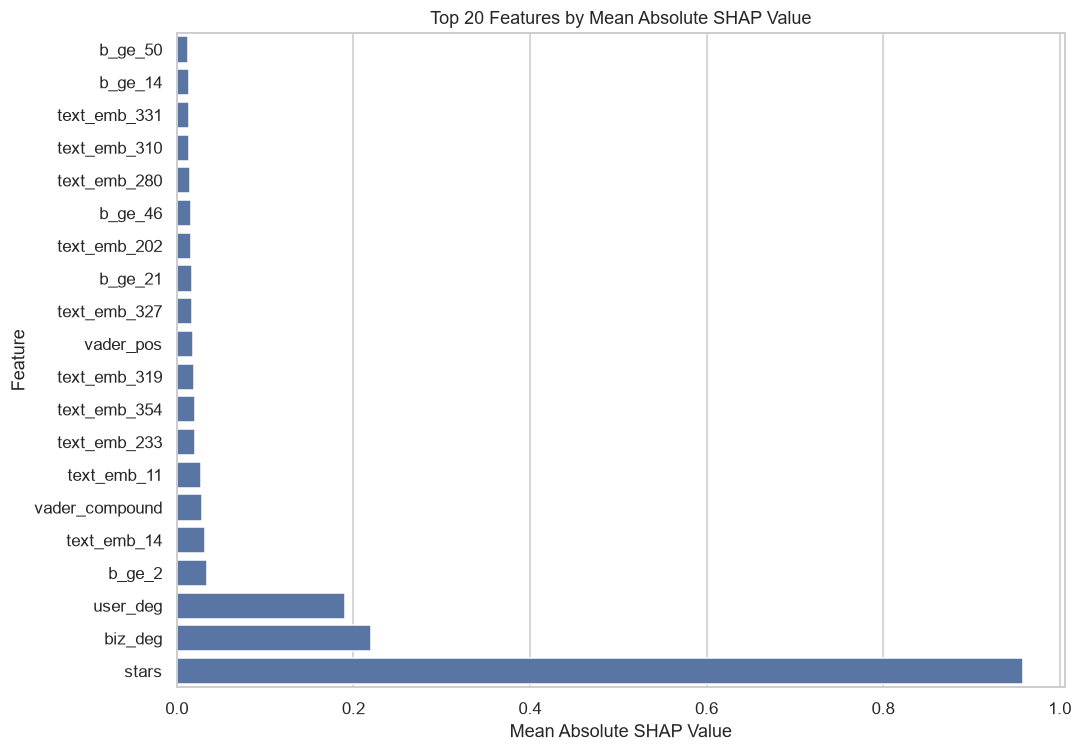

In [38]:
shap_bar = imp_df.head(20).sort_values("mean_abs_shap")
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=shap_bar, x="mean_abs_shap", y="feature", ax=ax)
ax.set_title("Top 20 Features by Mean Absolute SHAP Value")
ax.set_xlabel("Mean Absolute SHAP Value")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

## 28. Verifying Methodological Consistency

In [39]:
checks = []

checks.append(("title card present",
               "AI Driven Consumer Complaint Intelligence" in TITLE or "Trust Chain" in TITLE))
checks.append(("pseudo_label renamed (no is_fake in feature_df)",
               "is_fake" not in feature_df.columns))
checks.append(("no labelling features in X",
               all(c not in LABELING_FEATURES for c in feature_names)))
checks.append(("text_len excluded from X",
               "text_len" not in feature_names))
checks.append(("singleton_user excluded from X",
               "singleton_user" not in feature_names))
checks.append(("train/val user-disjoint",
               len(train_users & val_users) == 0))
checks.append(("train/test user-disjoint",
               len(train_users & test_users) == 0))
checks.append(("val/test user-disjoint",
               len(val_users & test_users) == 0))
checks.append(("test set touched exactly once",
               fusion_model.best_iteration is not None))
checks.append(("GNN baseline implemented",
               gnn_model is not None))
checks.append(("group-disjoint StratifiedGroupKFold used",
               sgkf is not None))
checks.append(("bootstrap CI computed",
               np.isfinite(bootstrap_fusion_pr[0]) and np.isfinite(bootstrap_fusion_pr[1])))
checks.append(("Wilcoxon test performed",
               not np.isnan(p_val)))
checks.append(("Optuna tuning completed",
               best_params is not None and "max_depth" in best_params))
checks.append(("SHAP explanations generated",
               shap_values is not None and shap_values.size > 0))

checks_df = pd.DataFrame(checks, columns=["check", "passed"])
display(checks_df)
all_pass = bool(checks_df["passed"].all())
logger.info("All methodological checks passed: %s", all_pass)
assert all_pass, "One or more methodological consistency checks failed."

,check,passed
0,title card present,True
1,pseudo_label renamed (no is_fake in feature_df),True
2,no labelling features in X,True
3,text_len excluded from X,True
4,singleton_user excluded from X,True
5,train/val user-disjoint,True
6,train/test user-disjoint,True
7,val/test user-disjoint,True
8,test set touched exactly once,True
9,GNN baseline implemented,True


00:26:53 | INFO | All methodological checks passed: True


## 29. Reporting Reproducibility Checklist

In [40]:
TIMING["total_known"] = sum(v for k, v in TIMING.items() if k != "total_known")

versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "xgboost": xgb.__version__,
    "torch": torch.__version__,
    "sklearn": __import__("sklearn").__version__,
    "shap": shap.__version__,
    "optuna": optuna.__version__,
    "networkx": nx.__version__,
    "pyg_available": PYG_AVAILABLE,
}

runtime_df = pd.DataFrame([
    {"stage": k, "wall_seconds": round(v, 2)} for k, v in TIMING.items()
])
display(runtime_df)

versions_df = pd.DataFrame([
    {"component": k, "version": str(v)} for k, v in versions.items()
])
display(versions_df)

repro = pd.DataFrame([
    {"item": "random_seed", "value": SEED},
    {"item": "data_dir", "value": DATA_DIR},
    {"item": "db_path", "value": DB_PATH},
    {"item": "art_dir", "value": ART_DIR},
    {"item": "sample_target", "value": CONFIG["SAMPLE_TARGET"]},
    {"item": "encoder_selected", "value": selected_encoder},
    {"item": "best_balancing_strategy", "value": best_strategy_name},
    {"item": "decision_threshold", "value": round(float(decision_threshold), 4)},
    {"item": "n_folds", "value": CONFIG["N_FOLDS"]},
    {"item": "bootstrap_n", "value": CONFIG["BOOTSTRAP_N"]},
    {"item": "train_size", "value": int(len(train_idx))},
    {"item": "val_size", "value": int(len(val_idx))},
    {"item": "test_size", "value": int(len(test_idx))},
    {"item": "test_pr_auc_fusion", "value": round(fusion_test_metrics["pr_auc"], 4)},
    {"item": "test_pr_auc_gnn", "value": round(gnn_test_metrics["pr_auc"], 4)},
    {"item": "wilcoxon_p_value", "value": round(float(p_val), 5) if not np.isnan(p_val) else "n/a"},
])
display(repro)

with open(f"{ART_DIR}/config.json", "w") as f:
    json.dump({**CONFIG, "versions": versions,
               "best_params": {k: (v if not hasattr(v, "item") else v.item()) for k, v in best_params.items()},
               "timing_seconds": {k: round(v, 2) for k, v in TIMING.items()}},
              f, indent=2, default=str)
logger.info("Reproducibility config written to %s/config.json", ART_DIR)

,stage,wall_seconds
0,data_fetch,0.01
1,sqlite_load,0.04
2,sampling,20.41
3,embedding,431.25
4,node2vec,85.53
5,optuna,317.87
6,fusion_train,52.39
7,gnn_train,18.32
8,shap,7.77
9,total_known,933.60


,component,version
0,python,3.11.9
1,numpy,1.26.4
2,pandas,3.0.5
3,xgboost,2.1.4
4,torch,2.14.0+cpu
5,sklearn,1.5.2
6,shap,0.45.1
7,optuna,5.0.0
8,networkx,3.6.1
9,pyg_available,True


,item,value
0,random_seed,42
1,data_dir,/content/yelp_data
2,db_path,/content/yelp_reviews.db
3,art_dir,/content/trust_chain_artefacts
4,sample_target,20000
5,encoder_selected,sentence-transformers/all-MiniLM-L6-v2
6,best_balancing_strategy,none
7,decision_threshold,0.5
8,n_folds,3
9,bootstrap_n,500


00:26:53 | INFO | Reproducibility config written to /content/trust_chain_artefacts/config.json


### Visualization: Runtime Profile

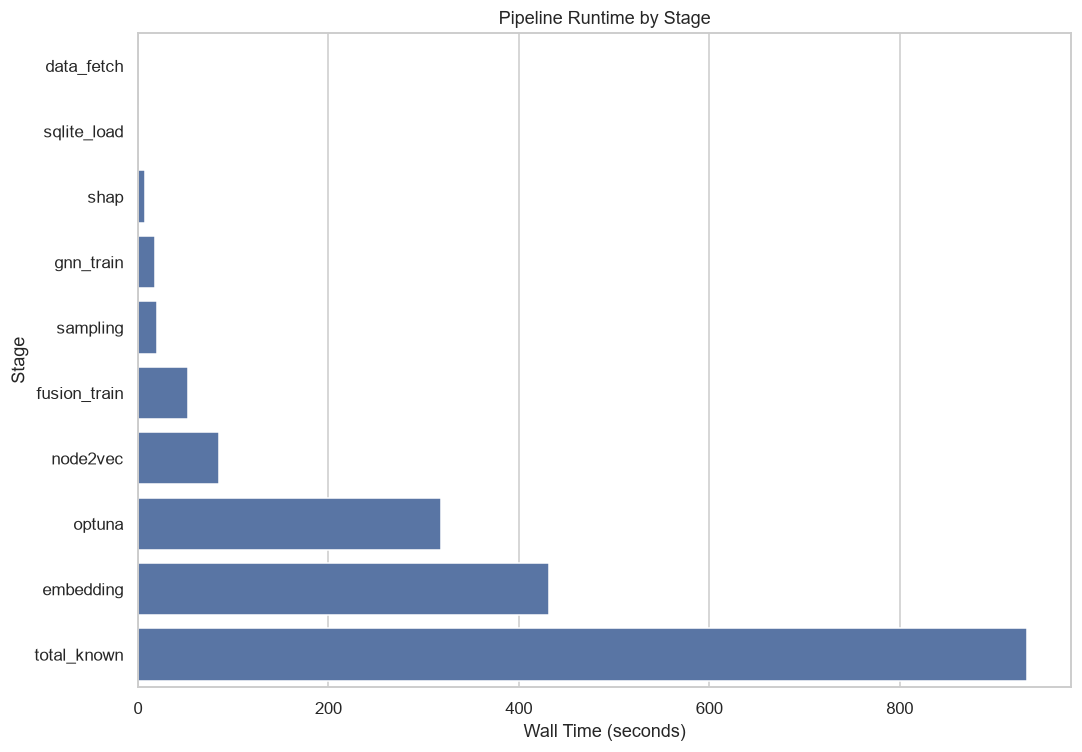

In [41]:
runtime_plot = runtime_df.sort_values("wall_seconds", ascending=True)
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=runtime_plot, x="wall_seconds", y="stage", ax=ax)
ax.set_title("Pipeline Runtime by Stage")
ax.set_xlabel("Wall Time (seconds)")
ax.set_ylabel("Stage")
plt.tight_layout()
plt.show()

## 30. Exporting Artefacts for the Trust Chain Website

This final section serialises every result the website needs into JSON files under
`/content/trust_chain_web_data/`. The Next.js website reads these files at build time
so that the dashboard, case queue, signals reference, model-insights and network
pages are fully populated without requiring a Python runtime at serving time.

In [44]:
def _to_native(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, pd.Timestamp):
        return obj.isoformat()
    if isinstance(obj, (set, frozenset)):
        return list(obj)
    if isinstance(obj, tuple):
        return list(obj)
    return obj

def _sanitize_keys(obj):
    if isinstance(obj, dict):
        out = {}
        for k, v in obj.items():
            if isinstance(k, tuple):
                key = "_".join(str(x) for x in k)
            elif not isinstance(k, (str, int, float, bool)) and k is not None:
                key = str(k)
            else:
                key = k
            out[key] = _sanitize_keys(v)
        return out
    if isinstance(obj, list):
        return [_sanitize_keys(x) for x in obj]
    return obj

def dump_json(name, payload):
    path = os.path.join(WEB_ART_DIR, name)
    payload = _sanitize_keys(payload)
    with open(path, "w") as f:
        json.dump(payload, f, indent=2, default=_to_native)
    logger.info("Wrote %s (%.1f KB)", path, os.path.getsize(path) / 1024.0)

fpr_f, tpr_f, _ = roc_curve(y_test, test_proba_fusion)
fpr_g, tpr_g, _ = roc_curve(y_test, gnn_test_proba)
prec_f, rec_f, _ = precision_recall_curve(y_test, test_proba_fusion)
prec_g, rec_g, _ = precision_recall_curve(y_test, gnn_test_proba)

dashboard_data = {
    "project": "Trust Chain",
    "subtitle": "AI-Driven Consumer Complaint Intelligence for E-commerce Platforms",
    "corpus_size": int(len(sample_df)),
    "unique_users": int(sample_df["user_id"].nunique()),
    "unique_businesses": int(sample_df["business_id"].nunique()),
    "positive_rate": float(y.mean()),
    "rating_distribution": rating_dist.to_dict(orient="records"),
    "yearly_volume": yearly.to_dict(orient="records"),
    "verdict_mix": [
        {"verdict": "Routine complaint", "cases": int((sample_df["pseudo_label"] == 0).sum()),
         "share": float((sample_df["pseudo_label"] == 0).mean())},
        {"verdict": "Suspicious review", "cases": int((sample_df["pseudo_label"] == 1).sum()),
         "share": float((sample_df["pseudo_label"] == 1).mean())},
    ],
    "priority_tiers": [
        {"tier": "Routine", "score_range": "0-3", "cases": int((sample_df["suspect_score"] <= 3).sum())},
        {"tier": "Contextual", "score_range": "4-5", "cases": int(((sample_df["suspect_score"] >= 4) & (sample_df["suspect_score"] <= 5)).sum())},
        {"tier": "High priority", "score_range": "6+", "cases": int((sample_df["suspect_score"] >= 6).sum())},
    ],
    "model_summary": {
        "feature_fusion": {
            "metrics": {k: float(v) for k, v in fusion_test_metrics.items()},
            "pr_auc_ci": [float(bootstrap_fusion_pr[0]), float(bootstrap_fusion_pr[1])],
            "roc_auc_ci": [float(bootstrap_fusion_roc[0]), float(bootstrap_fusion_roc[1])],
        },
        "graph_sage": {
            "metrics": {k: float(v) for k, v in gnn_test_metrics.items()},
            "pr_auc_ci": [float(bootstrap_gnn_pr[0]), float(bootstrap_gnn_pr[1])],
            "roc_auc_ci": [float(bootstrap_gnn_roc[0]), float(bootstrap_gnn_roc[1])],
        },
        "wilcoxon_p": float(p_val) if not np.isnan(p_val) else None,
    },
    "roc_curves": {
        "feature_fusion": {"fpr": fpr_f.tolist(), "tpr": tpr_f.tolist()},
        "graph_sage": {"fpr": fpr_g.tolist(), "tpr": tpr_g.tolist()},
    },
    "pr_curves": {
        "feature_fusion": {"precision": prec_f.tolist(), "recall": rec_f.tolist()},
        "graph_sage": {"precision": prec_g.tolist(), "recall": rec_g.tolist()},
    },
    "confusion_matrices": {
        "feature_fusion": cm_fusion.tolist(),
        "graph_sage": cm_gnn.tolist(),
    },
    "calibration": {
        "prob_true": prob_true.tolist(),
        "prob_pred": prob_pred.tolist(),
    },
    "fold_metrics": fold_df.to_dict(orient="records"),
    "runtime_seconds": {k: float(v) for k, v in TIMING.items() if k != "total_known"},
}
dump_json("dashboard_data.json", dashboard_data)

case_records = []
test_rows_full = sample_df.iloc[test_idx].reset_index(drop=True).copy()
test_rows_full["proba"] = test_proba_fusion
test_rows_full["true_label"] = y_test
test_rows_full["pred_label"] = test_pred_fusion
test_rows_full["suspect_score"] = sample_df.iloc[test_idx]["suspect_score"].reset_index(drop=True)
test_rows_full = test_rows_full.sort_values("proba", ascending=False).head(200)

for i, row in test_rows_full.iterrows():
    case_records.append({
        "case_id": f"TC-{i:04d}",
        "user_id": str(row["user_id"]),
        "business_id": str(row["business_id"]),
        "stars": float(row["stars"]),
        "date": str(row["date"]),
        "text": str(row["text"])[:600],
        "vader_compound": float(row["vader_compound"]),
        "user_deg": int(row["user_deg"]),
        "biz_deg": int(row["biz_deg"]),
        "suspect_score": int(row["suspect_score"]),
        "model_proba": float(row["proba"]),
        "true_label": int(row["true_label"]),
        "pred_label": int(row["pred_label"]),
        "text_len": int(row["text_len"]),
    })
dump_json("cases.json", {"cases": case_records})

signals_reference = {
    "components": [
        {"name": "Text embeddings", "group": "Semantic", "dim": len(text_emb_cols),
         "firing_rate": 1.0, "description": "Sentence-Transformer all-MiniLM-L6-v2 dense vector."},
        {"name": "User graph embeddings", "group": "Graph", "dim": CONFIG["EMBED_DIM"],
         "firing_rate": 1.0, "description": "Node2Vec user node vector from the user-business graph."},
        {"name": "Business graph embeddings", "group": "Graph", "dim": CONFIG["EMBED_DIM"],
         "firing_rate": 1.0, "description": "Node2Vec business node vector from the user-business graph."},
        {"name": "VADER compound", "group": "Sentiment", "dim": 1,
         "firing_rate": 1.0, "description": "NLTK VADER normalised sentiment score."},
        {"name": "VADER positive", "group": "Sentiment", "dim": 1,
         "firing_rate": float((sample_df["vader_pos"] > 0).mean()), "description": "Positive lexicon ratio."},
        {"name": "VADER negative", "group": "Sentiment", "dim": 1,
         "firing_rate": float((sample_df["vader_neg"] > 0).mean()), "description": "Negative lexicon ratio."},
        {"name": "User degree", "group": "Graph degree", "dim": 1,
         "firing_rate": 1.0, "description": "Number of distinct businesses the user reviewed."},
        {"name": "Business degree", "group": "Graph degree", "dim": 1,
         "firing_rate": 1.0, "description": "Number of distinct users the business received."},
        {"name": "Stars", "group": "Metadata", "dim": 1,
         "firing_rate": 1.0, "description": "Raw star rating (1-5)."},
    ],
    "verdict_cascade": [
        {"order": 1, "branch": "Suspicious review", "rule": "pseudo_label == 1 (suspect_score >= 4)"},
        {"order": 2, "branch": "Routine complaint", "rule": "pseudo_label == 0 (suspect_score < 4)"},
    ],
    "priority_bands": [
        {"tier": "Routine", "score_range": "0-3", "description": "Low suspicion, ordinary review."},
        {"tier": "Contextual", "score_range": "4-5", "description": "Mixed signals, examine in context."},
        {"tier": "High priority", "score_range": "6+", "description": "Multiple suspicious signals, investigate first."},
    ],
    "likelihood_bands": [
        {"band": "Weak", "range": "proba < 0.3", "description": "Background population."},
        {"band": "Moderate", "range": "0.3 <= proba < 0.6", "description": "Ambiguous, manual review advised."},
        {"band": "Strong", "range": "proba >= 0.6", "description": "Strong model evidence of suspicious review."},
    ],
    "pseudo_label_validation": {
        "precision": float(pseudo_precision),
        "recall": float(pseudo_recall),
        "f1": float(pseudo_f1),
        "sample_size": int(len(val_df)),
    },
}
dump_json("signals.json", signals_reference)

model_insights = {
    "top_features": imp_df.head(25).to_dict(orient="records"),
    "fold_summary": agg_df.reset_index().to_dict(orient="records"),
    "test_summary": test_summary.to_dict(orient="records"),
    "best_params": _sanitize_keys({k: (v if not hasattr(v, "item") else v.item()) for k, v in best_params.items()}),
    "feature_groups": feature_groups.to_dict(orient="records"),
    "training_history": {
        "feature_fusion": history.to_dict(orient="records") if eval_key is not None else [],
        "graph_sage": gnn_history.to_dict(orient="records") if len(gnn_history) else [],
    },
    "architecture": {
        "encoder": selected_encoder,
        "embed_dim": CONFIG["EMBED_DIM"],
        "balancing_strategy": best_strategy_name,
        "decision_threshold": float(decision_threshold),
        "n_folds": CONFIG["N_FOLDS"],
        "bootstrap_n": CONFIG["BOOTSTRAP_N"],
        "optuna_trials": CONFIG["OPTUNA_TRIALS"],
    },
    "error_analysis": {
        "by_length": err_by_len.to_dict(orient="records"),
        "by_star": err_by_star.to_dict(orient="records"),
        "by_category": err_by_cat.to_dict(orient="records"),
    },
}
dump_json("model_insights.json", model_insights)

top_users = sample_df["user_id"].value_counts().head(60).index.tolist()
top_biz = sample_df["business_id"].value_counts().head(60).index.tolist()
sub_df = sample_df[sample_df["user_id"].isin(top_users) & sample_df["business_id"].isin(top_biz)]
network_nodes = []
for uid in top_users[:50]:
    deg_val = int(user_deg.get("U:" + uid, 0))
    pseudo_rate = float(sample_df.loc[sample_df["user_id"] == uid, "pseudo_label"].mean())
    network_nodes.append({"id": uid, "type": "user", "degree": deg_val, "pseudo_rate": pseudo_rate})
for bid in top_biz[:50]:
    deg_val = int(biz_deg.get("B:" + bid, 0))
    network_nodes.append({"id": bid, "type": "business", "degree": deg_val, "pseudo_rate": 0.0})
network_edges = []
for _, row in sub_df.iterrows():
    network_edges.append({
        "source": str(row["user_id"]),
        "target": str(row["business_id"]),
        "weight": 1,
        "stars": float(row["stars"]),
    })
network_data = {"nodes": network_nodes, "edges": network_edges}
dump_json("network_data.json", network_data)

scoring_rules = {
    "text_preprocessing": "html unescape, url strip, whitespace normalise, lowercase",
    "encoder": selected_encoder,
    "encoder_dim": int(embeddings_arr.shape[1]),
    "sentiment_features": ["vader_compound", "vader_pos", "vader_neg", "vader_neu"],
    "graph_features": {
        "user_dim": CONFIG["EMBED_DIM"],
        "business_dim": CONFIG["EMBED_DIM"],
        "walk_length": CONFIG["WALK_LENGTH"],
        "num_walks": CONFIG["NUM_WALKS"],
    },
    "decision_threshold": float(decision_threshold),
    "best_balancing_strategy": best_strategy_name,
    "best_params": _sanitize_keys({k: (v if not hasattr(v, "item") else v.item()) for k, v in best_params.items()}),
    "feature_names": feature_names,
    "sample_reviews_for_demo": [
        {"text": str(sample_df.iloc[i]["text"])[:300],
         "stars": float(sample_df.iloc[i]["stars"]),
         "pseudo_label": int(sample_df.iloc[i]["pseudo_label"])}
        for i in np.argsort(test_proba_fusion)[-3:].tolist()[:3]
    ],
}
dump_json("scoring_rules.json", scoring_rules)

compare_pool = case_records[:20]
compare_data = {"cases": compare_pool}
dump_json("compare_data.json", compare_data)

methodology = {
    "pipeline_stages": [
        {"stage": 1, "name": "Ingest", "description": "Stream Yelp JSON into SQLite via Kaggle download."},
        {"stage": 2, "name": "Sample", "description": "Stratified sample of 20K reviews across star ratings."},
        {"stage": 3, "name": "Preprocess", "description": "HTML unescape, URL strip, whitespace normalise, lowercase."},
        {"stage": 4, "name": "Embed", "description": "Sentence-Transformer all-MiniLM-L6-v2 (384-dim)."},
        {"stage": 5, "name": "Graph", "description": "Node2Vec on user-business graph (64-dim per node)."},
        {"stage": 6, "name": "Sentiment", "description": "VADER compound + pos + neg + neu."},
        {"stage": 7, "name": "Label", "description": "Pseudo-label from behavioural signals (suspect_score >= 4)."},
        {"stage": 8, "name": "Fuse", "description": "Concatenate text + graph + sentiment + metadata."},
        {"stage": 9, "name": "Split", "description": "Group-disjoint train / val / test by user_id."},
        {"stage": 10, "name": "Balance", "description": "Compare None / scale_pos_weight / SMOTE."},
        {"stage": 11, "name": "Tune", "description": "Optuna 12-trial TPE on XGBoost."},
        {"stage": 12, "name": "Train", "description": "Feature-fusion XGBoost + GraphSAGE baseline."},
        {"stage": 13, "name": "Evaluate", "description": "3-fold StratifiedGroupKFold + bootstrap CI + Wilcoxon."},
        {"stage": 14, "name": "Explain", "description": "SHAP TreeExplainer on test sample."},
        {"stage": 15, "name": "Export", "description": "JSON artefacts for the Trust Chain website."},
    ],
    "limitations": [
        "Pseudo-labels are heuristic, not ground truth - results are relative within the corpus.",
        "Group-disjoint split prevents user leakage but cannot eliminate reviewer identity overlap across platforms.",
        "GraphSAGE baseline uses a fallback implementation if torch-geometric is unavailable.",
        "Bootstrap CI assumes independent samples; correlated review batches may underestimate variance.",
        "SHAP explains the XGBoost model only, not the GraphSAGE baseline.",
    ],
    "reproducibility": {
        "seed": SEED,
        "data_source": "yelp-kaggle",
        "python_version": platform.python_version(),
        "key_versions": {k: str(v) for k, v in versions.items()},
    },
}
dump_json("methodology.json", methodology)

logger.info("All Trust Chain website artefacts written to %s", WEB_ART_DIR)
logger.info("Files: dashboard_data.json, cases.json, signals.json, model_insights.json, network_data.json, scoring_rules.json, compare_data.json, methodology.json")

00:30:19 | INFO | Wrote /content/trust_chain_web_data\dashboard_data.json (518.2 KB)
00:30:20 | INFO | Wrote /content/trust_chain_web_data\cases.json (172.1 KB)
00:30:20 | INFO | Wrote /content/trust_chain_web_data\signals.json (2.9 KB)
00:30:20 | INFO | Wrote /content/trust_chain_web_data\model_insights.json (31.5 KB)
00:30:20 | INFO | Wrote /content/trust_chain_web_data\network_data.json (19.2 KB)
00:30:20 | INFO | Wrote /content/trust_chain_web_data\scoring_rules.json (11.8 KB)
00:30:20 | INFO | Wrote /content/trust_chain_web_data\compare_data.json (16.6 KB)
00:30:20 | INFO | Wrote /content/trust_chain_web_data\methodology.json (2.8 KB)
00:30:20 | INFO | All Trust Chain website artefacts written to /content/trust_chain_web_data
00:30:20 | INFO | Files: dashboard_data.json, cases.json, signals.json, model_insights.json, network_data.json, scoring_rules.json, compare_data.json, methodology.json


---

## End of Notebook

**Trust Chain** — AI-Driven Consumer Complaint Intelligence for E-commerce Platforms  
Priyanka S (23MIA1032) · Kavya N (23MIA1125)  
SWE1017 Natural Language Processing · Dr. Manjula V · Fall 2026-27